# Load data and model

In [1]:
%load_ext autoreload
%autoreload 2

import os
import sys
import pickle
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from torch import nn
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.interpolate import interp1d
from scipy.spatial.distance import pdist, squareform
import scipy.stats as stats
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D
import matplotlib.cm as cm
import matplotlib.colors as mcolors
from mpl_toolkits.mplot3d.art3d import Line3DCollection
from sklearn.decomposition import PCA
from sklearn.linear_model import Ridge, RidgeClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, balanced_accuracy_score
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# sys.path.append(os.path.expanduser('~/Documents/code/utils'))
# sys.path.append(os.path.expanduser('~/Documents/code/digitalbat'))
sys.path.append('/mnt/scratch09/yongrong/projects/bat-intelligence/src/digitalbat')

from digitalbat.utility.utils import (
    set_random_state, bat_palette, parse_bat, corr,
    poisson_fde_population, poisson_fde_population_filtered,
)
from digitalbat.datasets.data import bat_data_loader
from digitalbat.datasets.defaults import DEFAULT_SESSION_NAMES, make_data_config
from digitalbat.datasets.kinematics import make_joint_dataloaders
from digitalbat.models.joint import JointMaskedTransformer
from digitalbat.utility.utils import list_pad_concatenate, compute_angles, generate_landmark_dicts
from digitalbat.utility.utils import stars_for_p, add_significance_bracket
from digitalbat.utility.utils import FlightDMD, FlightDMDAnalyzer, FlightDMDPostAnalysis

# import notebook_helpers as nh
# import plotting_helpers as ph
# ph.set_pub_style()
# ph.FIG_DIR = Path('out/figures')

seed = 1
set_random_state(seed)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device)

# # Canonical display name for the joint encode/decode transformer (used in all labels).
# HIPPO_NEDS = 'Hippo-NEDS'

device: cuda


In [2]:
# for plot figures
# sns.set_theme(context='talk', style='ticks')
plt.rcParams.update({'figure.max_open_warning': 0})
#Output matplotlib figure to SVG with text as text, not curves
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['pdf.fonttype'] = 42   # editable text in Illustrator

from digitalbat.utility.utils import bat_palette

def route_palette():
    """Return a `{route_label: rgb_or_color_name}` dict in canonical order."""
    ROUTE_LABELS = ["Rew->Rew", "Rew->Per", "Per->Rew", "Per->Per", "Other"]
    ROUTE_COLORS = ['firebrick', 'darkorange', 'forestgreen', 'steelblue', 'gray']
    
    return {label: color for label, color in zip(ROUTE_LABELS, ROUTE_COLORS)}

def motif_palette():
    """Return a `{motif_label: color}` dict in canonical order."""
    MOTIF_LABELS = ["Away", "Toward", "Other"]
    MOTIF_COLORS = ['#377eb8', '#e41a1c', 'gray']  # Blue (Away), Red (Toward), Gray (Other)
    return {label: color for label, color in zip(MOTIF_LABELS, MOTIF_COLORS)}

def route_palette_motif():
    """Return a `{f_type_label: color}` dict in canonical order for motifs."""
    ROUTE_LABELS = ["Rew->Per", "Rew->Half", "Per->Rew", "Half->Rew", "Other"]
    ROUTE_COLORS = ['darkorange', 'firebrick', 'forestgreen', 'mediumseagreen', 'gray']
    return {label: color for label, color in zip(ROUTE_LABELS, ROUTE_COLORS)}

def landmark_palette():
    """Return a `{landmark_label: rgb_or_color_name}` dict in canonical order."""
    LANDMARK_LABELS = ["Start@Rew", "End@Rew", "Start@Per", "End@Per", "Start@Other", "End@Other"]
    # Choosing an intuitive color scheme (greens for start, reds/corals for end, gray for other)
    LANDMARK_COLORS = ['forestgreen', 'firebrick', 'mediumseagreen', 'tomato', 'darkgray', 'lightgray']
    return {label: color for label, color in zip(LANDMARK_LABELS, LANDMARK_COLORS)}

# Create color maps for the hierarchy sidebars
def get_color_sidebar(df, column, palette="tab10"):
    # Get unique values from the original data
    keys = df[column].unique()
    # Create the color lookup table
    lut = dict(zip(keys, sns.color_palette(palette, len(keys))))
    # CAST TO OBJECT: This prevents the Categorical mapping error
    return df[column].astype(object).map(lut)

# Convert hex/named colors to numeric RGB values so imshow handles it cleanly
def colors_to_rgb_array(df):
    from matplotlib.colors import to_rgb
    return np.array([[to_rgb(c) for c in df[col]] for col in df.columns]).transpose(1, 0, 2)

In [3]:
# 17 DEFAULT_SESSIONS, position-only (behavior_dim == 3).
EXCLUDED_SESSIONS = {'Dataset_3_14543_240419'}
session_names = [s for s in DEFAULT_SESSION_NAMES if s not in EXCLUDED_SESSIONS]

PARENT_FOLDER = '/mnt/at-globusshare/Users/Yongrong/'
max_acceleration = 50.0
data_config = make_data_config(session_names=session_names, parent_folder=PARENT_FOLDER, max_acceleration=max_acceleration)
session_names = data_config['session_names']
bin_width = data_config['bin_width']

# Single load in the joint model's *training* universe. make_joint_dataloaders
# loads once (kinematics on) and returns the position-only view `dl_pos` plus the
# shared meta. We use this ONE universe for BOTH the encode and decode arms so
# every analysis shares one flight_path_index (no cross-universe remapping). The
# tradeoff vs the plain position-only loader is that a few tail flights with short
# IMU are dropped — negligible, and it matches how the model was trained.
dataloaders, _dl_kin, unit_num_dict, meta_info_dict = make_joint_dataloaders(data_config)
behavior_dim = 3

# bats = ph.bat_order()
# BAT_PALETTE = ph.bat_pal()
n_neurons_total = sum(unit_num_dict.values())
print(f'{len(session_names)} sessions | {n_neurons_total} neurons | behavior_dim={behavior_dim}')
# print('neurons/session:', {s: unit_num_dict[s] for s in session_names[:3]}, '...')

  Acceleration filter: removed 1/136 flights (peak |acc| > 50.0 m/s²)
  Acceleration filter: removed 9/154 flights (peak |acc| > 50.0 m/s²)
  Acceleration filter: removed 4/131 flights (peak |acc| > 50.0 m/s²)
  Acceleration filter: removed 1/79 flights (peak |acc| > 50.0 m/s²)
  Acceleration filter: removed 1/78 flights (peak |acc| > 50.0 m/s²)
  Acceleration filter: removed 1/77 flights (peak |acc| > 50.0 m/s²)
  Acceleration filter: removed 4/82 flights (peak |acc| > 50.0 m/s²)
  Acceleration filter: removed 1/98 flights (peak |acc| > 50.0 m/s²)
  Acceleration filter: removed 4/112 flights (peak |acc| > 50.0 m/s²)
17 sessions | 3080 neurons | behavior_dim=3


In [4]:
dataloaders

{'train': {'Dataset_3_14543_240420': <torch.utils.data.dataloader.DataLoader at 0x7f8e66ddbad0>,
  'Dataset_3_14543_240421': <torch.utils.data.dataloader.DataLoader at 0x7f8e5da4a630>,
  'Dataset_3_29959_240402': <torch.utils.data.dataloader.DataLoader at 0x7f8e5da4bf80>,
  'Dataset_3_29959_240403': <torch.utils.data.dataloader.DataLoader at 0x7f8e5da484a0>,
  'Dataset_3_29959_240404': <torch.utils.data.dataloader.DataLoader at 0x7f8e5da4a240>,
  'Dataset_2_14445_231208': <torch.utils.data.dataloader.DataLoader at 0x7f8e5da48d40>,
  'Dataset_2_14445_231209': <torch.utils.data.dataloader.DataLoader at 0x7f8e5da49460>,
  'Dataset_1_32622_231009': <torch.utils.data.dataloader.DataLoader at 0x7f8e5da499d0>,
  'Dataset_1_32622_231010': <torch.utils.data.dataloader.DataLoader at 0x7f8e5da486b0>,
  'Dataset_1_32622_231007': <torch.utils.data.dataloader.DataLoader at 0x7f8e5da4a4e0>,
  'Dataset_2_14611_231208': <torch.utils.data.dataloader.DataLoader at 0x7f8e5da48b30>,
  'Dataset_2_14611_2312

In [5]:
unit_num_dict, meta_info_dict.keys()

({'Dataset_3_14543_240420': 126,
  'Dataset_3_14543_240421': 100,
  'Dataset_3_29959_240402': 317,
  'Dataset_3_29959_240403': 191,
  'Dataset_3_29959_240404': 190,
  'Dataset_2_14445_231208': 237,
  'Dataset_2_14445_231209': 168,
  'Dataset_1_32622_231009': 95,
  'Dataset_1_32622_231010': 54,
  'Dataset_1_32622_231007': 167,
  'Dataset_2_14611_231208': 236,
  'Dataset_2_14611_231209': 186,
  'Dataset_3_00000_240402': 394,
  'Dataset_3_00000_240403': 207,
  'Dataset_3_00000_240404': 147,
  'Dataset_3_00000_240405': 122,
  'Dataset_3_29959_240405': 143},
 dict_keys(['r_lim', 'flight_type_test_indomain', 'flight_type_test_ood', 'behavior_mean', 'behavior_std', 'spike_std', 'spatial_centers_sigma', 'pType', 'probe_id', 'neuron_position']))

In [6]:
# --- Consensus model: the single joint encode/decode transformer used paper-wide
# (6-masking infill/forecast finetune; joint-encode-decode.ipynb §6.4).
JOINT_CKPT = ('./out/joint/joint_v2_cross1000_kin0_L4_d64_ff64_lam0.68_pw0.36_identity'
              '_we2.8_wd2.2_wa0.31_n17.pth')
JOINT_PARAMS = dict(num_layers=4, latent_dim=64, num_heads=4, ff_dim=64, dropout=0.2)
INPUT_TRANSFORM = 'identity'


def joint_session_room(s):
    """3-config room map (matches joint-encode-decode.ipynb `session_room`)."""
    if '_fs' in s:
        return 'krishna_fs'
    if s.startswith('Dataset_2_'):
        return 'dataset_2'
    return 'lab'


session_to_room = {s: joint_session_room(s) for s in unit_num_dict}

set_random_state(seed)
if os.path.exists(JOINT_CKPT):
    joint_model = JointMaskedTransformer(
        unit_num_dict, behavior_dim=3, input_transform=INPUT_TRANSFORM,
        session_to_room=session_to_room, **JOINT_PARAMS).to(device)
    joint_model.load_state_dict(torch.load(JOINT_CKPT, map_location=device))
    joint_model = joint_model.eval()
else:
    # Train-if-missing: 200-trial Optuna search (use_kinematics=False, fde_weight=0.5),
    # then train the winner. Reproduces the consensus checkpoint named above.
    from digitalbat.training.joint_trainer import ensure_joint_model
    joint_model, _jp, JOINT_CKPT = ensure_joint_model(
        dataloaders, unit_num_dict, session_to_room, meta_info_dict, device,
        seed=seed, out_dir='./out/joint', n_trials=200)
    JOINT_PARAMS = dict(num_layers=_jp['num_layers'], latent_dim=_jp['latent_dim'],
                        num_heads=4, ff_dim=_jp['ff_dim'], dropout=_jp['dropout'])

# Encode and decode arms share ONE flight universe (see the data-load cell), so the
# decode-arm loaders/meta are simply the shared ones — no separate universe.
joint_loaders, joint_meta = dataloaders, meta_info_dict
print('consensus joint model ready:', JOINT_CKPT)

consensus joint model ready: ./out/joint/joint_v2_cross1000_kin0_L4_d64_ff64_lam0.68_pw0.36_identity_we2.8_wd2.2_wa0.31_n17.pth


In [7]:
joint_model

JointMaskedTransformer(
  (spike_readin): ModuleDict(
    (Dataset_3_14543_240420): Linear(in_features=126, out_features=64, bias=True)
    (Dataset_3_14543_240421): Linear(in_features=100, out_features=64, bias=True)
    (Dataset_3_29959_240402): Linear(in_features=317, out_features=64, bias=True)
    (Dataset_3_29959_240403): Linear(in_features=191, out_features=64, bias=True)
    (Dataset_3_29959_240404): Linear(in_features=190, out_features=64, bias=True)
    (Dataset_2_14445_231208): Linear(in_features=237, out_features=64, bias=True)
    (Dataset_2_14445_231209): Linear(in_features=168, out_features=64, bias=True)
    (Dataset_1_32622_231009): Linear(in_features=95, out_features=64, bias=True)
    (Dataset_1_32622_231010): Linear(in_features=54, out_features=64, bias=True)
    (Dataset_1_32622_231007): Linear(in_features=167, out_features=64, bias=True)
    (Dataset_2_14611_231208): Linear(in_features=236, out_features=64, bias=True)
    (Dataset_2_14611_231209): Linear(in_featur

# Generate features for analysis

In [8]:
N_RESAMPLED = 50  # Fixed time points per trajectory
MIN_LEN, MAX_LEN = 20, 100

def get_env(session_name):
    return "Outdoor" if "Dataset_2" in session_name else "Indoor"

In [9]:
# --- Extract latent representations via forward hook ---
joint_model.eval()

latent_dict = {}  # session -> (n_timepoints, latent_dim), encode
latent_d_dict = {}  # session -> (n_timepoints, latent_dec_dim), decode
xyz_dict = {}     # session -> (n_timepoints, 3)
rel_azimuth_dict = {}  # session -> (n_timepoints,), head direction, -180 deg ~ 180 deg
rel_elevation_dict = {} # session -> (n_timepoints,), head direction, -90 deg ~ 90 deg
flight_id_dict = {}  # session -> (n_timepoints,)
rel_time_dict = {}   # session -> (n_timepoints,) in [0, 1]
accel_dict = {}      # session -> (n_timepoints,) total acceleration
speed_dict = {}      # session -> (n_timepoints,) L2 velocity norm
cluster_dict = {}    # session -> (n_timepoints,) flight cluster type
session_label_dict = {}  # session -> (n_timepoints,) session name string
true_spike_dict = {} # session -> (n_timepoints, n_neurons), recorded spike counts
# saliency_dict = {} # session -> (n_timepoints_resp, n_timepoints_loc, n_neurons)

dt = data_config['bin_width']

for session_name, session_data in dataloaders['test'].items():
    latents_session, xyz_session, fid_session, rtime_session, accel_session, speed_session, cluster_session, slabel_session = [], [], [], [], [], [], [], []
    latents_d_session = []
    true_spike_session = []
    rel_azimuth_session, rel_elevation_session = [], []
    # saliency_session = []

    with torch.no_grad():
        for batch in session_data:
            mask = batch.mask.to(device); T = batch.spike.shape[1]
            nt = batch.mask.clone().to(device); bt = torch.zeros_like(nt)
            # encode pass
            spike0 = torch.zeros_like(batch.spike.to(device))
            _, _, xfull = joint_model(session_name, spike0, batch.behavior.to(device), mask, nt, bt)
            h = xfull[:, :T] 
            m = batch.mask.bool()
            latents_session.append(h[m.to(device)].cpu().numpy())
            # decode pass: real spikes visible, behaviour masked -> decode latent
            behavior0 = torch.zeros_like(batch.behavior.to(device))
            _, _, xfull_d = joint_model(session_name, batch.spike.to(device), behavior0, mask, torch.zeros_like(mask), mask)
            h_d = xfull_d[:, :T] # encode space too: neural tokens x[:, :T] (decode pass)
            latents_d_session.append(h_d[m.to(device)].cpu().numpy())

            pos = batch.behavior[:, :, :3].numpy()  # (B, T, 3)
            # Convert z-scored position back to meters
            bm = meta_info_dict['behavior_mean'][session_name]  # (1, 1, D)
            bs = meta_info_dict['behavior_std'][session_name]
            pos_meters = pos * bs[0, 0, :3] + bm[0, 0, :3]
            xyz_session.append(pos_meters[m.cpu().numpy()])

            # azimuth and elevation
            head_dir = np.diff(pos, axis=1, prepend=0) # pos - pos[:, 0, :][:, None, :]
            head_dir = head_dir[m.cpu().numpy()]
            rel_azimuth, rel_elevation = compute_angles(head_dir)
            rel_azimuth_session.append(rel_azimuth)
            rel_elevation_session.append(rel_elevation)
            
            # Total velocity and acceleration via np.gradient
            spd = np.zeros(pos.shape[:2])  # (B, T)
            acc = np.zeros(pos.shape[:2])  # (B, T)
            for bi in range(pos.shape[0]):
                vel = np.gradient(pos[bi], dt, axis=0)   # (T, 3)
                a = np.gradient(vel, dt, axis=0)          # (T, 3)
                spd[bi] = np.linalg.norm(vel, axis=1)
                acc[bi] = np.linalg.norm(a, axis=1)
            speed_session.append(spd[m.cpu().numpy()])
            accel_session.append(acc[m.cpu().numpy()])

            # Flight path index per valid timestep
            fpi = batch.flight_path_index  # (B,)
            fpi_expanded = fpi.unsqueeze(1).expand_as(batch.mask)  # (B, T)
            fid_session.append(fpi_expanded[m].numpy())
            # Flight cluster type per valid timestep
            fti = batch.flight_type_index  # (B,)
            fti_expanded = fti.unsqueeze(1).expand_as(batch.mask)  # (B, T)
            cluster_session.append(fti_expanded[m].numpy())
            # Session label per valid timestep
            slabel_session.append(np.full(m.sum().item(), session_name))
            # Relative time within each flight: 0 at start, 1 at end
            T = batch.mask.shape[1]
            t_grid = torch.arange(T, dtype=torch.float32).unsqueeze(0).expand_as(batch.mask)
            n_valid = batch.mask.sum(dim=1, keepdim=True).clamp(min=2)  # (B, 1)
            rel_t = t_grid / (n_valid - 1)
            rtime_session.append(rel_t[m].numpy())

            # recorded spike counts
            true_spike_session.append(batch.spike.detach()[batch.mask.detach() == 1.0].cpu().numpy()) # (T, Neuron)

    latent_dict[session_name] = np.concatenate(latents_session)
    latent_d_dict[session_name] = np.concatenate(latents_d_session)
    xyz_dict[session_name] = np.concatenate(xyz_session)
    rel_azimuth_dict[session_name] = np.concatenate(rel_azimuth_session)
    rel_elevation_dict[session_name] = np.concatenate(rel_elevation_session)
    flight_id_dict[session_name] = np.concatenate(fid_session)
    rel_time_dict[session_name] = np.concatenate(rtime_session)
    accel_dict[session_name] = np.concatenate(accel_session)
    speed_dict[session_name] = np.concatenate(speed_session)
    cluster_dict[session_name] = np.concatenate(cluster_session)
    session_label_dict[session_name] = np.concatenate(slabel_session)
    true_spike_dict[session_name] = np.concatenate(true_spike_session)

# Concatenate across all sessions
all_latents = np.concatenate(list(latent_dict.values()))
all_latents_dec = np.concatenate(list(latent_d_dict.values()))
all_xyz = np.concatenate(list(xyz_dict.values()))
all_rel_azimuth = np.concatenate(list(rel_azimuth_dict.values()))
all_rel_elevation = np.concatenate(list(rel_elevation_dict.values()))
all_rel_time = np.concatenate(list(rel_time_dict.values()))
all_accel = np.concatenate(list(accel_dict.values()))
all_speed = np.concatenate(list(speed_dict.values()))
all_cluster = np.concatenate(list(cluster_dict.values()))
all_session = np.concatenate(list(session_label_dict.values()))
all_flight_id = np.concatenate(list(flight_id_dict.values()))
all_true_spike = list_pad_concatenate(list(true_spike_dict.values()))
# all_saliency = list_pad_concatenate(list(saliency_dict.values()))

# Derived categorical labels
import re
all_bat = np.array([re.search(r'_(\d{5})_', s).group(1) for s in all_session])
all_cluster_session = np.array([f'{s}_c{int(c)}' for s, c in zip(all_session, all_cluster)])
all_flight_session = np.array([f'{s}_f{int(f)}' for s, f in zip(all_session, all_flight_id)])
print(f'Latent shape: {all_latents.shape}, Latent_dec shape: {all_latents_dec.shape}, XYZ shape: {all_xyz.shape}, all_true_spike.shape: {all_true_spike.shape}')
print(f'Unique bats: {len(np.unique(all_bat))}, sessions: {len(np.unique(all_session))}, '
      f'cluster-sessions: {len(np.unique(all_cluster_session))}, flight-sessions: {len(np.unique(all_flight_session))}')
print(f'all_cluster_session: {all_cluster_session}')

Latent shape: (8072, 64), Latent_dec shape: (8072, 64), XYZ shape: (8072, 3), all_true_spike.shape: (8072, 394)
Unique bats: 6, sessions: 17, cluster-sessions: 131, flight-sessions: 278
all_cluster_session: ['Dataset_3_14543_240420_c3' 'Dataset_3_14543_240420_c3'
 'Dataset_3_14543_240420_c3' ... 'Dataset_3_29959_240405_c6'
 'Dataset_3_29959_240405_c6' 'Dataset_3_29959_240405_c6']


In [10]:
# PCA
pca3 = PCA(n_components=3).fit(all_latents)
all_latents_pca3 = pca3.transform(all_latents)
print(f'PCA: first 3 PCs explain {pca3.explained_variance_ratio_.sum():.1%} of variance')

pca3 = PCA(n_components=3).fit(all_latents_dec)
all_latents_dec_pca3 = pca3.transform(all_latents_dec)
print(f'PCA: first 3 PCs explain {pca3.explained_variance_ratio_.sum():.1%} of variance')

PCA: first 3 PCs explain 27.4% of variance
PCA: first 3 PCs explain 29.0% of variance


In [11]:
from digitalbat.utility.utils import decode_spikes_to_latent
all_spike_in_latent = decode_spikes_to_latent(all_true_spike, all_latents, all_session)
# PCA
pca3 = PCA(n_components=3).fit(all_spike_in_latent)
all_spike_in_latent_pca3 = pca3.transform(all_spike_in_latent)
print(f'PCA: first 3 PCs explain {pca3.explained_variance_ratio_.sum():.1%} of variance')

Starting latent reconstruction across 17 sessions...



Session Dataset_1_32622_231007 | Neurons: 167 | Mean Test $R^2$: 0.373
Session Dataset_1_32622_231009 | Neurons: 95 | Mean Test $R^2$: 0.357
Session Dataset_1_32622_231010 | Neurons: 54 | Mean Test $R^2$: 0.373
Session Dataset_2_14445_231208 | Neurons: 237 | Mean Test $R^2$: 0.518
Session Dataset_2_14445_231209 | Neurons: 168 | Mean Test $R^2$: 0.489
Session Dataset_2_14611_231208 | Neurons: 236 | Mean Test $R^2$: 0.467
Session Dataset_2_14611_231209 | Neurons: 186 | Mean Test $R^2$: 0.543
Session Dataset_3_00000_240402 | Neurons: 394 | Mean Test $R^2$: 0.579
Session Dataset_3_00000_240403 | Neurons: 207 | Mean Test $R^2$: 0.563
Session Dataset_3_00000_240404 | Neurons: 147 | Mean Test $R^2$: 0.459
Session Dataset_3_00000_240405 | Neurons: 122 | Mean Test $R^2$: 0.373
Session Dataset_3_14543_240420 | Neurons: 126 | Mean Test $R^2$: 0.454
Session Dataset_3_14543_240421 | Neurons: 100 | Mean Test $R^2$: 0.423
Session Dataset_3_29959_240402 | Neurons: 317 | Mean Test $R^2$: 0.393
Session 

In [12]:
# landmark locations (reward and perch) in physical space 
# Dataset1 and Dataset3 use the same landmarks
# Dataset1 and Dataset3 have two reward locations and one perch location (though two are given, but we use a Logical OR 
# operation to include any locations with a Euclidean distance < 0.3 m)
landmark_phy = {
    'Dataset_1': dict(
        rew_locs=np.array([
            [2.80, -0.86, 1.57],
            [2.75,  0.96, 1.57],
        ]),
        perch_locs=np.array([
            [-2.55, 1.57, 1.82],
            [-1.98, 2.08, 1.74],
        ]),
    ),
    'Dataset_3': dict(
        rew_locs=np.array([
            [2.80, -0.86, 1.57],
            [2.75,  0.96, 1.57],
        ]),
        perch_locs=np.array([
            [-2.55, 1.57, 1.82],
            [-1.98, 2.08, 1.74],
        ]),
    ),
    'Dataset_2': dict(
        rew_locs=np.array([
            [-3.00, 0.70, 1.90],
        ]),
        perch_locs=np.array([
            [-3.20, 1.80, 2.20],
        ]),
    ),
}

threshold = 0.6
reward_dict, perch_dict = generate_landmark_dicts(xyz_dict, landmark_phy, threshold=threshold)
all_reward = np.concatenate(list(reward_dict.values()))
all_perch = np.concatenate(list(perch_dict.values()))

# RSA on trajectory

In [28]:
# 1. Find the indices where a new trajectory starts (where rel_time is 0.0)
start_indices = np.where(all_rel_time == 0.0)[0]
# 2. Append the total length of the array to capture the length of the last trajectory
end_indices = np.append(start_indices, len(all_rel_time))
# 3. Calculate the length of each trajectory by taking the difference between consecutive start indices
trajectory_lengths = np.diff(end_indices)
# 4. Compute the median
median_length = np.median(trajectory_lengths)
mean_length = np.mean(trajectory_lengths)
#
print(f"Total Trajectories: {len(trajectory_lengths)}")
print(f"Median Trajectory Length: {median_length:.2f} time points")
print(f"Mean Trajectory Length: {mean_length:.2f} time points")
print(f"Min/Max Length: {trajectory_lengths.min()} / {trajectory_lengths.max()}")

Total Trajectories: 278
Median Trajectory Length: 23.00 time points
Mean Trajectory Length: 29.04 time points
Min/Max Length: 13 / 118


In [29]:
# Define the same mapping logic to ensure colors match exactly
def get_legend_handles(df, column, palette, title):
    keys = df[column].unique()
    # Use the same palette logic as before
    colors = sns.color_palette(palette, len(keys))
    lut = dict(zip(keys, colors))
    handles = [mpatches.Patch(color='none', label=f"[{title}]")]
    for key, color in lut.items():
        handles.append(mpatches.Patch(color=color, label=str(key)))
    return handles
def get_legend_handles_from_dict(color_dict, title):
    """Generates legend handles from a fixed dictionary."""
    handles = [mpatches.Patch(color='none', label=f"[{title}]")]
    for key, color in color_dict.items():
        handles.append(mpatches.Patch(color=color, label=str(key)))
    return handles

def compute_hausdorff(trajectory_1, trajectory_2, metric='euclidean'):
    """
    Compute the bidirectional Hausdorff distance between two trajectories.
    
    Parameters
    ----------
    trajectory_1 : np.ndarray of shape (T1, D)
    trajectory_2 : np.ndarray of shape (T2, D)
    metric : str
        Distance metric supported by scipy.spatial.distance.cdist 
        (e.g., 'euclidean', 'cosine', 'correlation').
        
    Returns
    -------
    float
        The Hausdorff distance.
    """
    from scipy.spatial.distance import cdist
    # 1. Compute the pairwise distance matrix between all points of both trajectories
    # Shape of pdist_matrix will be (T1, T2)
    pdist_matrix = cdist(trajectory_1, trajectory_2, metric=metric)
    # 2. For each point in T1, find the minimum distance to any point in T2, then find the max
    # np.min axis=1 finds the closest point in T2 for every point in T1
    forward_hd = np.max(np.min(pdist_matrix, axis=1))
    # 3. For each point in T2, find the minimum distance to any point in T1, then find the max
    # np.min axis=0 finds the closest point in T1 for every point in T2
    backward_hd = np.max(np.min(pdist_matrix, axis=0))
    # 4. The bidirectional Hausdorff distance is the maximum of the two
    return max(forward_hd, backward_hd)

def compute_similarity_matrix(all_features, metric='cosine', compute_matrix_flag=True):
    """
    all_features: can be all_latents: (L, 32), all_xyz: (L, 3), all_latents_pca3: (L, 3)
    """
    # Find trajectory boundaries (where rel_time resets to 0)
    resets = np.where(all_rel_time == 0)[0]
    boundaries = np.append(resets, len(all_rel_time))
    trajectories = []
    metadata = []
    for i in range(len(boundaries) - 1):
        start, end = boundaries[i], boundaries[i+1]
        length = end - start    
        if MIN_LEN <= length <= MAX_LEN:
            # Extract latent slice
            traj_latents = all_features[start:end] # all_latents: (L, 32); all_latents_pca3: (L, 3) 

            # Determine Flight Type
            is_rew = all_reward[start:end]
            is_per = all_perch[start:end]
            if is_rew[0] and is_per[-1]: f_type = "Rew->Per"
            elif is_per[0] and is_rew[-1]: f_type = "Per->Rew"
            elif is_rew[0] and is_rew[-1]: f_type = "Rew->Rew"
            elif is_per[0] and is_per[-1]: f_type = "Per->Per"
            else: f_type = "Other"

            # trajectories.append(resampled_latent.flatten()) # Flatten to (1600,)
            trajectories.append(traj_latents) 
            metadata.append({
                'env': get_env(all_session[start]),
                'f_type': f_type,
                'bat': all_bat[start],
                'session': all_session[start],
                's_cluster': all_cluster_session[start],
            })
    # --- 2. Sorting & Hierarchy ---
    df_meta = pd.DataFrame(metadata)
    # Define categorical order for sorting
    df_meta['env'] = pd.Categorical(df_meta['env'], categories=['Indoor', 'Outdoor'])
    df_meta['f_type'] = pd.Categorical(df_meta['f_type'], 
                                    categories=["Rew->Rew", "Rew->Per", "Per->Rew", "Per->Per", "Other"])
    # Sort by the hierarchy: Env -> Flight Type -> Bat -> Session
    df_meta = df_meta.sort_values(['env', 'f_type', 'bat', 'session', 's_cluster'])
    sorted_indices = df_meta.index.values

    # --- Matrix Generation Code ---
    # 1. Sort the trajectories
    sorted_trajectories = [trajectories[i] for i in sorted_indices]
    # 2. Initialize the matrix
    num_trajectories = len(sorted_trajectories)
    dist_matrix = np.zeros((num_trajectories, num_trajectories))
    # 3. Choose your metric ('euclidean', 'cosine', or 'correlation')
    # 4. Populate the matrix using the upper triangle optimization
    if compute_matrix_flag:
        for i in range(num_trajectories):
            for j in range(i + 1, num_trajectories):
                dist = compute_hausdorff(sorted_trajectories[i], sorted_trajectories[j], metric=metric)
                dist_matrix[i, j] = dist
                dist_matrix[j, i] = dist

    similarity_matrix = 1 - dist_matrix
    return sorted_trajectories, similarity_matrix, df_meta


# --- Data Generation / Inputs (from your snippet) ---
traj_xyz, sim_mat_xyz, df_meta_xyz = compute_similarity_matrix(all_xyz, metric='euclidean')
_, sim_mat_spike, _ = compute_similarity_matrix(all_spike_in_latent, metric='cosine')
_, sim_mat_latents_dec, _ = compute_similarity_matrix(all_latents_dec, metric='cosine')
_, sim_mat_latents, _ = compute_similarity_matrix(all_latents, metric='cosine')

traj_azimuth, _, _ = compute_similarity_matrix(all_rel_azimuth, metric='euclidean', compute_matrix_flag=False)
traj_spike_in_latent_pca3, _, _ = compute_similarity_matrix(all_spike_in_latent_pca3, metric='cosine', compute_matrix_flag=False)
traj_latents_dec_pca3, _, _ = compute_similarity_matrix(all_latents_dec_pca3, metric='cosine', compute_matrix_flag=False)
traj_latents_pca3, _, _ = compute_similarity_matrix(all_latents_pca3, metric='cosine', compute_matrix_flag=False)

traj_list = [traj_xyz, traj_spike_in_latent_pca3, traj_latents_dec_pca3, traj_latents_pca3]
sim_mat_list = [sim_mat_xyz, sim_mat_spike, sim_mat_latents_dec, sim_mat_latents]
df_meta_list = [df_meta_xyz, ] * len(sim_mat_list)
df_meta = df_meta_list[0]
titles = ["Physical", "Spikes in latents", "TWIN decode", "TWIN encode"]

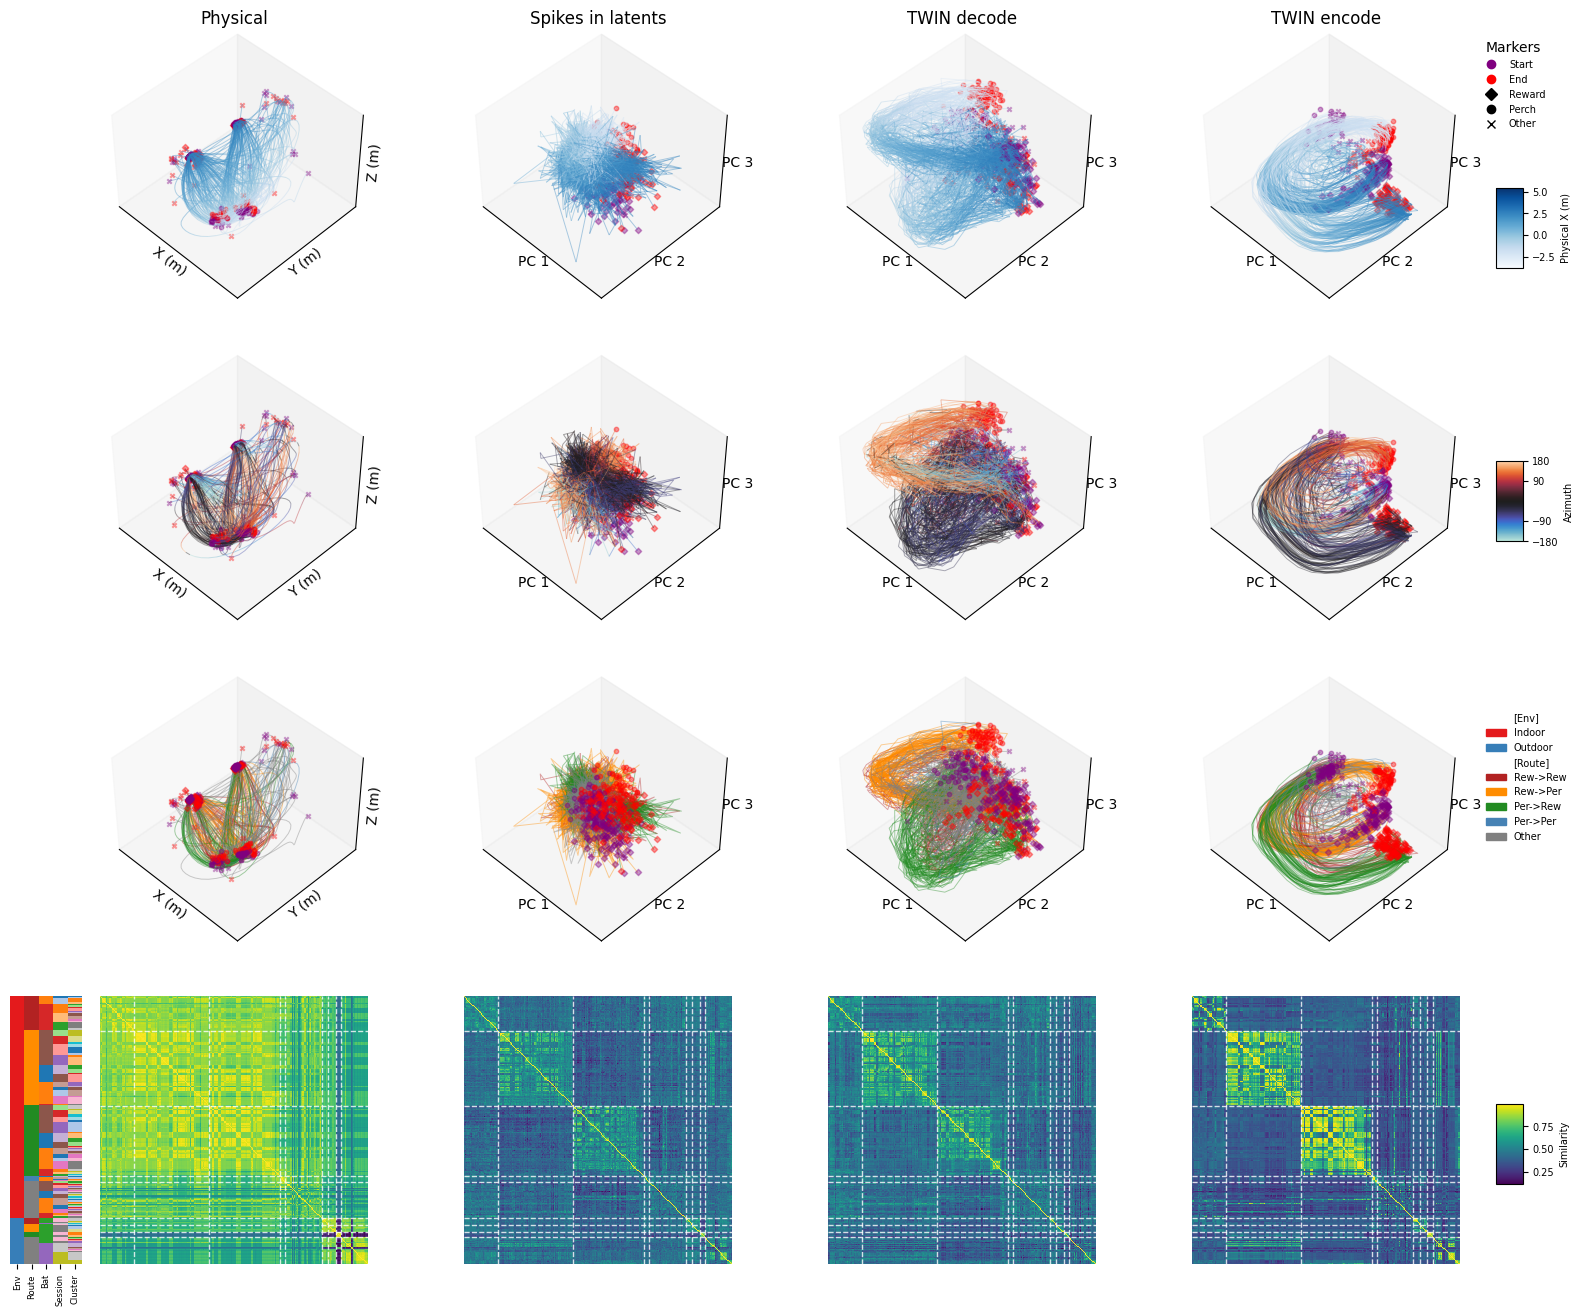

In [30]:
axislabels = [['X (m)', 'Y (m)', 'Z (m)'], ['PC 1', 'PC 2', 'PC 3'], ['PC 1', 'PC 2', 'PC 3'], ['PC 1', 'PC 2', 'PC 3']]
num_cols = len(sim_mat_list)
# --- Calculate Route Boundaries ---
f_type_series = df_meta['f_type'].values
route_boundaries = np.where(f_type_series[:-1] != f_type_series[1:])[0] + 1
# --- Build the shared Sidebar DataFrame ---
env_colors = get_color_sidebar(df_meta, 'env', "Set1").tolist()
type_colors = df_meta['f_type'].map(route_palette()).tolist()
bat_colors = df_meta['bat'].map(bat_palette()).tolist()
session_colors = get_color_sidebar(df_meta, 'session', "tab20").tolist()
s_cluster_colors = get_color_sidebar(df_meta, 's_cluster', "tab20").tolist()
sidebar_df = pd.DataFrame({
    "Env": env_colors,
    "Route": type_colors,
    "Bat": bat_colors,
    "Session": session_colors,
    "Cluster": s_cluster_colors,
}, index=df_meta.index)
sidebar_rgb = colors_to_rgb_array(sidebar_df)

# 1. Initialize 2x3 Figure Structure
nrows = 4
fig = plt.figure(figsize=(4 * num_cols + 2, 4 * nrows))
axes_row1 = []  # 3D Trajectories
axes_row2 = []  # 3D Trajectories
axes_row3 = []  # 3D Trajectories
axes_row4 = []  # Heatmaps
for i in range(num_cols):
    # Row 1 setup (New: 3D plots colored by X)
    ax_3d_r1 = fig.add_subplot(nrows, num_cols, i + 1, projection='3d')
    axes_row1.append(ax_3d_r1)
    # Row 2 setup (3D plots colored by azimuth)
    ax_3d_r2 = fig.add_subplot(nrows, num_cols, num_cols + i + 1, projection='3d')
    axes_row2.append(ax_3d_r2)
    # Row 3 setup (3D plots colored by Route Type)
    ax_3d_r3 = fig.add_subplot(nrows, num_cols, 2 * num_cols + i + 1, projection='3d')
    axes_row3.append(ax_3d_r3)
    # Row 4 setup (2D Heatmaps)
    ax_2d = fig.add_subplot(nrows, num_cols, 3 * num_cols + i + 1)
    axes_row4.append(ax_2d)
set_view_flag = True # whether to set view for the 3d plot
elev=45; azim=135

# --- 2. Plot Row 1: 3D Trajectories colored by traj_xyz X coordinates ---
env_series = df_meta['env'].values  # Needed to check for 'Indoor' restriction
# Flatten all x coordinates of traj_xyz to find the global min and max for consistent scaling
all_x_coords = np.concatenate([t[:, 0] for t in traj_list[0]])
norm = mcolors.Normalize(vmin=np.min(all_x_coords), vmax=np.max(all_x_coords))
cmap = cm.Blues  # You can change 'viridis' to any matplotlib colormap (e.g., 'plasma', 'coolwarm')
for i in range(num_cols):
    ax = axes_row1[i]
    trajectories = traj_list[i]
    # Keep spatial references linked specifically to the physical coordinates (traj_list[0])
    xyz_trajectories = traj_list[0]
    for t_idx, traj in enumerate(trajectories):
        if env_series[t_idx] != 'Indoor':
            continue
        # Color each segment of the trajectory based on the corresponding X coordinate in traj_xyz
        xyz_traj = xyz_trajectories[t_idx]
        x_coords = xyz_traj[:, 0]
        points = traj.reshape(-1, 1, 3)
        segments = np.concatenate([points[:-1], points[1:]], axis=1)
        # Use the average X coordinate of each segment to determine its color
        segment_x = 0.5 * (x_coords[:-1] + x_coords[1:])
        colors = cmap(norm(segment_x))
        lc = Line3DCollection(segments, colors=colors, alpha=0.4, linewidth=0.7, zorder=5, rasterized=True)
        ax.add_collection3d(lc)
        # Mark flight starts and ends based on f_type logic
        f_type = f_type_series[t_idx]
        if f_type.startswith("Rew"): start_marker = 'D'
        elif f_type.startswith("Per"): start_marker = 'o'
        else: start_marker = 'x'
        if f_type.endswith("Rew"): end_marker = 'D'
        elif f_type.endswith("Per"): end_marker = 'o'
        else: end_marker = 'x'
        ax.scatter(traj[0, 0], traj[0, 1], traj[0, 2], color='purple', marker=start_marker, s=10, alpha=0.4, zorder=4)
        ax.scatter(traj[-1, 0], traj[-1, 1], traj[-1, 2], color='red', marker=end_marker, s=10, alpha=0.4, zorder=4)
    ax.set_title(f"{titles[i]}")
    ax.grid(False)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_zticks([])
    ax.set_xlabel(axislabels[i][0], labelpad=-15)
    ax.set_ylabel(axislabels[i][1], labelpad=-15)
    ax.set_zlabel(axislabels[i][2], labelpad=-15)
    traj_arrays = np.concatenate([t for t in trajectories])
    ax.set_xlim([np.min(traj_arrays[:,0]), np.max(traj_arrays[:,0])])
    ax.set_ylim([np.min(traj_arrays[:,1]), np.max(traj_arrays[:,1])])
    ax.set_zlim([np.min(traj_arrays[:,2]), np.max(traj_arrays[:,2])])
    if set_view_flag:
        ax.view_init(elev=elev, azim=azim)

# --- Last Column Legend (3D Plot Markers) ---
marker_h = [
    Line2D([0], [0], marker='o', color='none', markerfacecolor='purple', markeredgecolor='purple', label='Start'),
    Line2D([0], [0], marker='o', color='none', markerfacecolor='red', markeredgecolor='red', label='End'),
    Line2D([0], [0], marker='D', color='none', markerfacecolor='black', markeredgecolor='black', label='Reward'),
    Line2D([0], [0], marker='o', color='none', markerfacecolor='black', markeredgecolor='black', label='Perch'),
    Line2D([0], [0], marker='x', color='none', markerfacecolor='black', markeredgecolor='black', label='Other')
]
# Attach directly to the 3D axes on the top-right corner
axes_row1[-1].legend(
    handles=marker_h,
    loc='upper left',
    bbox_to_anchor=(1.05, 1.0),  # Places it right next to the 3D plot boundaries
    frameon=False,
    fontsize=7,
    title="Markers",
    # title_fontsize=8
)
# --- Colorbar for Row 1, Last Column (X-Coordinate) ---
last_3d_r1_ax = axes_row1[-1]
r1_pos = last_3d_r1_ax.get_position()
# Create a dedicated axes for the colorbar next to the 3D plot
cbar_r1_ax = fig.add_axes([
    r1_pos.x1 + 0.02, 
    r1_pos.y0 + 0.02, 
    0.015, 
    r1_pos.height * 0.3
])
# Generate the colorbar using the ScalarMappable tied to the X-coordinate normalization
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar_r1 = fig.colorbar(sm, cax=cbar_r1_ax)
cbar_r1.set_label("Physical X (m)", fontsize=7)
cbar_r1.ax.tick_params(labelsize=7)


# --- 2. Plot Row 2: 3D Trajectories colored by azimuth ---
env_series = df_meta['env'].values  # Needed to check for 'Indoor' restriction
# Flatten all x coordinates of traj_xyz to find the global min and max for consistent scaling
all_x_coords = np.concatenate([t[:] for t in traj_azimuth])
norm = mcolors.Normalize(vmin=-180, vmax=180) # mcolors.Normalize(vmin=np.min(all_x_coords), vmax=np.max(all_x_coords))
cmap = plt.colormaps['icefire'] # cm.icefire  # You can change 'viridis' to any matplotlib colormap (e.g., 'plasma', 'coolwarm')
for i in range(num_cols):
    ax = axes_row2[i]
    trajectories = traj_list[i]
    # Keep spatial references linked specifically to the physical coordinates (traj_list[0])
    xyz_trajectories = traj_list[0]
    for t_idx, traj in enumerate(trajectories):
        if env_series[t_idx] != 'Indoor':
            continue
        # Color each segment of the trajectory based on the corresponding X coordinate in traj_xyz
        xyz_traj = xyz_trajectories[t_idx]
        x_coords = traj_azimuth[t_idx] # xyz_traj[:, 0]
        points = traj.reshape(-1, 1, 3)
        segments = np.concatenate([points[:-1], points[1:]], axis=1)
        # Use the average X coordinate of each segment to determine its color
        segment_x = 0.5 * (x_coords[:-1] + x_coords[1:])
        colors = cmap(norm(segment_x))
        lc = Line3DCollection(segments, colors=colors, alpha=0.4, linewidth=0.7, zorder=5, rasterized=True)
        ax.add_collection3d(lc)
        # Mark flight starts and ends based on f_type logic
        f_type = f_type_series[t_idx]
        if f_type.startswith("Rew"): start_marker = 'D'
        elif f_type.startswith("Per"): start_marker = 'o'
        else: start_marker = 'x'
        if f_type.endswith("Rew"): end_marker = 'D'
        elif f_type.endswith("Per"): end_marker = 'o'
        else: end_marker = 'x'
        ax.scatter(traj[0, 0], traj[0, 1], traj[0, 2], color='purple', marker=start_marker, s=10, alpha=0.4, zorder=4)
        ax.scatter(traj[-1, 0], traj[-1, 1], traj[-1, 2], color='red', marker=end_marker, s=10, alpha=0.4, zorder=4)
    # ax.set_title(f"{titles[i]}")
    ax.grid(False)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_zticks([])
    ax.set_xlabel(axislabels[i][0], labelpad=-15)
    ax.set_ylabel(axislabels[i][1], labelpad=-15)
    ax.set_zlabel(axislabels[i][2], labelpad=-15)
    traj_arrays = np.concatenate([t for t in trajectories])
    ax.set_xlim([np.min(traj_arrays[:,0]), np.max(traj_arrays[:,0])])
    ax.set_ylim([np.min(traj_arrays[:,1]), np.max(traj_arrays[:,1])])
    ax.set_zlim([np.min(traj_arrays[:,2]), np.max(traj_arrays[:,2])])
    if set_view_flag:
        ax.view_init(elev=elev, azim=azim)

# --- Colorbar for Row 1, Last Column (X-Coordinate) ---
last_3d_r1_ax = axes_row2[-1]
r1_pos = last_3d_r1_ax.get_position()
# Create a dedicated axes for the colorbar next to the 3D plot
cbar_r1_ax = fig.add_axes([
    r1_pos.x1 + 0.02, 
    r1_pos.y0 + 0.05, 
    0.015, 
    r1_pos.height * 0.3
])
# Generate the colorbar using the ScalarMappable tied to the X-coordinate normalization
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar_r1 = fig.colorbar(sm, cax=cbar_r1_ax, ticks=[-180, -90, 90, 180])
cbar_r1.set_label("Azimuth", fontsize=7)
cbar_r1.ax.tick_params(labelsize=7)


# 2. Plot Row 3: 3D Trajectories colored by Route Type
env_series = df_meta['env'].values  # Needed to check for 'Indoor' restriction
for i in range(num_cols):
    ax = axes_row3[i]
    trajectories = traj_list[i]
    # Iterate and plot individual 3D trajectories using matching row colors
    for t_idx, traj in enumerate(trajectories): # trajectories is a sorted list of traj
        # (1) Only include flights from 'Indoor' environment
        if env_series[t_idx] != 'Indoor':
            continue
        color = type_colors[t_idx]
        ax.plot(traj[:, 0], traj[:, 1], traj[:, 2], color=color, alpha=0.4, linewidth=0.7, zorder=5, rasterized=True)    
        # (3) Mark flight starts and ends based on f_type logic
        f_type = f_type_series[t_idx]
        # Determine start marker attributes
        if f_type.startswith("Rew"): start_marker = 'D'
        elif f_type.startswith("Per"): start_marker = 'o'
        else: start_marker = 'x'
        # Determine end marker attributes
        if f_type.endswith("Rew"): end_marker = 'D'
        elif f_type.endswith("Per"): end_marker = 'o'
        else: end_marker = 'x'
        # Plot markers at index 0 (Start) and index -1 (End)
        ax.scatter(traj[0, 0], traj[0, 1], traj[0, 2], color='purple', marker=start_marker, s=10, alpha=0.4, zorder=4)
        ax.scatter(traj[-1, 0], traj[-1, 1], traj[-1, 2], color='red', marker=end_marker, s=10, alpha=0.4, zorder=4)

    # ax.set_title(f"{titles[i]}")
    # Clean up 3D pane background and axes for presentation
    ax.grid(False)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_zticks([])
    # (2) Bring axis labels much closer to the axes using a negative labelpad
    ax.set_xlabel(axislabels[i][0], labelpad=-15)
    ax.set_ylabel(axislabels[i][1], labelpad=-15)
    ax.set_zlabel(axislabels[i][2], labelpad=-15)
    traj_arrays = np.concatenate([traj for traj in trajectories])
    ax.set_xlim([np.min(traj_arrays[:,0]), np.max(traj_arrays[:,0])])
    ax.set_ylim([np.min(traj_arrays[:,1]), np.max(traj_arrays[:,1])])
    ax.set_zlim([np.min(traj_arrays[:,2]), np.max(traj_arrays[:,2])])
    # Change the 3D viewing perspective (elevation and azimuth in degrees)
    if set_view_flag:
        ax.view_init(elev=elev, azim=azim)


# 3. Plot Row 4: RSA Heatmaps 
for i in range(num_cols):
    ax = axes_row4[i]
    sim_matrix = sim_mat_list[i]
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlabel('Flights (sorted)')
    # Calculate vmin and vmax excluding the diagonal values
    off_diagonal_vals = sim_matrix[~np.eye(sim_matrix.shape[0], dtype=bool)]
    v_min = np.min(off_diagonal_vals)
    v_max = np.max(off_diagonal_vals)
    # Draw the main similarity matrix (cbar=False for ALL to keep shapes identical)
    im = sns.heatmap(
        sim_matrix, ax=ax, cmap="viridis", cbar=False,
        vmin=v_min, vmax=v_max, xticklabels=False, yticklabels=False, square=True, rasterized=True
    )
    # Add the white dashed boundary lines across rows and columns
    for boundary in route_boundaries:
        ax.axhline(y=boundary, color='white', linestyle='--', linewidth=1.0, alpha=0.8)
        ax.axvline(x=boundary, color='white', linestyle='--', linewidth=1.0, alpha=0.8)
    # ax.set_title(titles[i])
plt.draw() # Force geometry calculations
# 4. Inject the Left Sidebar explicitly onto the first heatmap column
first_heatmap_ax = axes_row4[0]
heatmap_pos = first_heatmap_ax.get_position()
sidebar_width = 0.04
sidebar_padding = 0.01
sidebar_ax = fig.add_axes([
    heatmap_pos.x0 - sidebar_width - sidebar_padding, 
    heatmap_pos.y0, 
    sidebar_width, 
    heatmap_pos.height
])
sidebar_ax.imshow(sidebar_rgb, aspect='auto', interpolation='nearest')
sidebar_ax.set_xticks(range(len(sidebar_df.columns)))
sidebar_ax.set_xticklabels(sidebar_df.columns, rotation=90, fontsize=6)
sidebar_ax.set_yticks([])
sidebar_ax.spines[:].set_visible(False)
# 5. Position the Shared Colorbar and Legend on the last column
last_heatmap_ax = axes_row4[-1]
last_heatmap_pos = last_heatmap_ax.get_position()
cbar_width = 0.015
cbar_ax = fig.add_axes([
    last_heatmap_pos.x1 + 0.02, 
    last_heatmap_pos.y0 + 0.05, 
    cbar_width, 
    last_heatmap_pos.height * 0.3
])
cbar = fig.colorbar(last_heatmap_ax.collections[0], cax=cbar_ax)
cbar.set_label("Similarity", fontsize=7)
cbar.ax.tick_params(labelsize=7)
# 6. Row 2: Generate and position Shared Legend (only shown for the last column)
env_h = get_legend_handles(df_meta, 'env', "Set1", "Env")
type_h = get_legend_handles_from_dict(route_palette(), "Route")
bat_h = get_legend_handles_from_dict(bat_palette(), "Bat")
all_handles = env_h + type_h
fig.legend(
    handles=all_handles, 
    loc='upper left',
    bbox_to_anchor=(last_heatmap_pos.x1 + 0.01, last_heatmap_pos.y0 + 0.35),
    ncol=1, 
    frameon=False, 
    fontsize=7
)
# plt.savefig(f"./out-figures/fig2-RSA-on-trajectory.svg", dpi=300)
# plt.savefig(f"./out-figures/fig2-RSA-on-trajectory.png", dpi=300)

# Analyzing similarity matrix and latents

In [15]:
def calc_f_stat(dist_mat, labels):
    """
    Calculate F statistics
    """
    unique_labels = np.unique(labels)
    n_groups = len(unique_labels)
    n_samples = len(labels)
    # Degrees of freedom for F-distribution style ratio
    df_between = n_groups - 1
    df_within = n_samples - n_groups
    # Calculate total sum of squares (total variance)
    ss_total = np.sum(dist_mat**2) / (2 * n_samples)
    # Calculate within-group sum of squares
    ss_within = 0.0
    for r in unique_labels:
        r_mask = (labels == r)
        n_r = np.sum(r_mask)
        if n_r > 1:
            ss_within += np.sum(dist_mat[r_mask][:, r_mask]**2) / (2 * n_r)
    ss_between = ss_total - ss_within
    # F-statistic ratio (Between-group / Within-group MS)
    return (ss_between / df_between) / ((ss_within / df_within) + 1e-10)

def compute_f_stats_and_null(sim_mat_list, df_meta, titles, target_title="TWIN encode", env='Indoor', 
                             f_types=["Rew->Rew", "Rew->Per", "Per->Rew", "Per->Per"], 
                             n_permutations=1000):
    # Filter indices based on both environment and matching route types
    mask = (df_meta['env'] == env).values & df_meta['f_type'].isin(f_types).values
    routes = np.array(df_meta['f_type'].values[mask], copy=True) # Ensure clean NumPy array for stability
    n_samples = len(routes)
    # 1. First pass: compute all observed matrices and distance matrices
    obs_f_dict = {}
    dist_mats = {}
    for sim_mat, title in zip(sim_mat_list, titles):
        mat = sim_mat[mask][:, mask]
        dist_mat = np.ascontiguousarray(1 - mat)
        dist_mats[title] = dist_mat
        obs_f_dict[title] = calc_f_stat(dist_mat, routes)
    # Get target reference metrics
    target_obs_f = obs_f_dict[target_title]
    target_dist_mat = dist_mats[target_title]
    
    # 2. Second pass: compute permutation distributions and differences
    results = {}
    for title in titles:
        obs_f = obs_f_dict[title]
        if title == target_title:
            # Target comparison metrics are assigned None/empty values
            results[title] = {
                "observed_f": obs_f,
                "obs_diff": None,
                "null_diffs": np.zeros(n_permutations),
                "p_val": None
            }
            continue
        # Initialize calculations comparing this title with target_title
        current_dist_mat = dist_mats[title]
        obs_diff = obs_f - target_obs_f
        null_diffs = np.zeros(n_permutations)
        # Matrix swapping permutations
        for p in range(n_permutations):
            # Mask to randomly select rows/columns to swap identities between matrices
            swap_mask = np.random.rand(n_samples) > 0.5
            perm_current = current_dist_mat.copy()
            perm_target = target_dist_mat.copy()
            # Synchronously swap rows and columns between current and target matrices
            perm_current[swap_mask, :] = target_dist_mat[swap_mask, :]
            perm_target[swap_mask, :] = current_dist_mat[swap_mask, :]
            perm_current[:, swap_mask] = target_dist_mat[:, swap_mask]
            perm_target[:, swap_mask] = current_dist_mat[:, swap_mask]
            # Compute simulated difference under the null hypothesis
            null_diffs[p] = calc_f_stat(perm_current, routes) - calc_f_stat(perm_target, routes)
            
        # Calculate two-tailed p-value
        p_val = np.sum(np.abs(null_diffs) >= np.abs(obs_diff)) / n_permutations
        results[title] = {
            "observed_f": obs_f,
            "obs_diff": np.abs(obs_diff),
            "null_diffs": np.abs(null_diffs),
            "p_val": p_val
        }
        
    return results

In [16]:
class LatentDecoderPipeline:
    def __init__(self, min_len=10, max_len=200, alpha_grid=None):
        self.min_len = min_len
        self.max_len = max_len
        self.alpha_grid = alpha_grid if alpha_grid is not None else [0.01, 0.1, 1.0, 10.0, 100.0]
        self.valid_types = ["Rew->Rew", "Rew->Per", "Per->Rew", "Per->Per"]
        # Labels for continuous targets
        self.reg_labels = ['X', 'Y', 'Z', 'Velocity', 'Accel.', 'Azimuth', 'Elevation', 'Rel time']

    def preprocess_and_filter(self, all_latents, all_xyz, all_speed, all_accel, all_rel_time, all_reward, 
                              all_perch, all_rel_azimuth, all_rel_elevation, all_session):
        """Filters by environment (Indoor) and flight length, extracting valid trajectories."""
        resets = np.where(all_rel_time == 0)[0]
        boundaries = np.append(resets, len(all_rel_time))
        # all_speed = self._compute_velocity(all_xyz, boundaries)
        
        valid_trajectories = []
        for i in range(len(boundaries) - 1):
            start, end = boundaries[i], boundaries[i+1]
            length = end - start
            
            # Environment Check: 'Dataset_1' or 'Dataset_3' represents Indoor
            session_name = all_session[start]
            is_indoor = "Dataset_1" in session_name or "Dataset_3" in session_name
            
            if is_indoor and (self.min_len <= length <= self.max_len):
                # Classify Flight Type
                is_rew = all_reward[start:end]
                is_per = all_perch[start:end]
                
                if is_rew[0] and is_per[-1]: f_type = "Rew->Per"
                elif is_per[0] and is_rew[-1]: f_type = "Per->Rew"
                elif is_rew[0] and is_rew[-1]: f_type = "Rew->Rew"
                elif is_per[0] and is_per[-1]: f_type = "Per->Per"
                else: f_type = "Other"
                
                if f_type in self.valid_types:
                    traj_data = {
                        'latents': all_latents[start:end],
                        'xyz': all_xyz[start:end],
                        'speed': all_speed[start:end],
                        'acceleration': all_accel[start:end],
                        'azimuth': all_rel_azimuth[start:end],
                        'elevation': all_rel_elevation[start:end],
                        'rel_time': all_rel_time[start:end],
                        'f_type': f_type,
                        'f_type_idx': self.valid_types.index(f_type),
                        'length': length
                    }
                    valid_trajectories.append(traj_data)
                    
        print(f"Extracted {len(valid_trajectories)} valid Indoor flight trajectories.")
        return valid_trajectories

    def split_data_411(self, trajectories, seed=42):
        """Splits trajectory blocks using a fixed 4:1:1 ratio to avoid leakage."""
        np.random.seed(seed)
        shuffled_indices = np.random.permutation(len(trajectories))
        
        n_total = len(trajectories)
        n_val = n_total // 6
        n_test = n_total // 6
        n_train = n_total - n_val - n_test
        
        train_idx = shuffled_indices[:n_train]
        val_idx = shuffled_indices[n_train:n_train+n_val]
        test_idx = shuffled_indices[n_train+n_val:]
        
        def concatenate_blocks(indices):
            X = np.concatenate([trajectories[i]['latents'] for i in indices], axis=0)
            # Continuous targets
            xyz = np.concatenate([trajectories[i]['xyz'] for i in indices], axis=0)
            speed = np.concatenate([trajectories[i]['speed'] for i in indices], axis=0)[:, None]
            accel = np.concatenate([trajectories[i]['acceleration'] for i in indices], axis=0)[:, None]
            # --- Trigonometric Preprocessing for Angles ---
            az_rad = np.radians(np.concatenate([trajectories[i]['azimuth'] for i in indices], axis=0))
            el_rad = np.radians(np.concatenate([trajectories[i]['elevation'] for i in indices], axis=0))
            az_sin, az_cos = np.sin(az_rad)[:, None], np.cos(az_rad)[:, None]
            el_sin, el_cos = np.sin(el_rad)[:, None], np.cos(el_rad)[:, None]
            t = np.concatenate([trajectories[i]['rel_time'] for i in indices], axis=0)[:, None]
            # Y_reg shape is now (N, 10) instead of (N, 8)
            Y_reg = np.hstack([xyz, speed, accel, az_sin, az_cos, el_sin, el_cos, t])
            # Classification targets (broadcasted to matching length)
            Y_clf = np.concatenate([np.full(trajectories[i]['length'], trajectories[i]['f_type_idx']) for i in indices], axis=0)
            
            return X, Y_reg, Y_clf

        X_train, Y_reg_train, Y_clf_train = concatenate_blocks(train_idx)
        X_val, Y_reg_val, Y_clf_val = concatenate_blocks(val_idx)
        X_test, Y_reg_test, Y_clf_test = concatenate_blocks(test_idx)
        
        return (X_train, Y_reg_train, Y_clf_train, 
                X_val, Y_reg_val, Y_clf_val, 
                X_test, Y_reg_test, Y_clf_test)

    def run_pipeline(self, valid_trajectories):
        """Trains models, optimizes regularization parameters, and evaluates."""
        # 1. Train/Val/Test Separation
        data = self.split_data_411(valid_trajectories)
        X_train, Y_reg_train, Y_clf_train = data[0], data[1], data[2]
        X_val, Y_reg_val, Y_clf_val = data[3], data[4], data[5]
        X_test, Y_reg_test, Y_clf_test = data[6], data[7], data[8]
        
        # Scale neural features
        scaler = StandardScaler()
        X_train_scaled = scaler.fit_transform(X_train)
        X_val_scaled = scaler.transform(X_val)
        X_test_scaled = scaler.transform(X_test)

        y_scaler = StandardScaler()
        Y_reg_train = y_scaler.fit_transform(Y_reg_train)
        Y_reg_val = y_scaler.transform(Y_reg_val)
        Y_reg_test = y_scaler.transform(Y_reg_test)
        
        # --- PIPELINE A: Continuous Target Regression ---
        best_reg_alpha = None
        best_reg_score = -float('inf')
        for alpha in self.alpha_grid:
            model = Ridge(alpha=alpha)
            model.fit(X_train_scaled, Y_reg_train)
            val_preds = model.predict(X_val_scaled)
            score = r2_score(Y_reg_val, val_preds) # overall tracking metric
            if score > best_reg_score:
                best_reg_score = score
                best_reg_alpha = alpha   
        final_reg_model = Ridge(alpha=best_reg_alpha)
        final_reg_model.fit(X_train_scaled, Y_reg_train)
        test_reg_preds = final_reg_model.predict(X_test_scaled)

        # Map back the 10 predicted outputs to your 8 continuous variables
        raw_reg_weights = np.abs(final_reg_model.coef_) # Shape: (10, 32)
        
        # We compute average R2 score and average attribution weights across sin/cos components
        processed_r2 = {}
        processed_weights = []
        # Explicit mapping index logic for the 10 columns: 
        # [0: X, 1: Y, 2: Z, 3: Vel, 4: Acc, 5: Az_sin, 6: Az_cos, 7: El_sin, 8: El_cos, 9: Time]
        indices_map = {
            'X': [0], 'Y': [1], 'Z': [2], 'Velocity': [3], 'Accel.': [4],
            'Azimuth': [5, 6], 'Elevation': [7, 8], 'Rel time': [9]
        }
        for name in self.reg_labels:
            indices = indices_map[name]
            # Average R2 across components
            r2_val = np.mean([r2_score(Y_reg_test[:, idx], test_reg_preds[:, idx]) for idx in indices])
            processed_r2[name] = r2_val
            # Average attribution weights
            weight_val = np.mean(raw_reg_weights[indices, :], axis=0)
            processed_weights.append(weight_val)
        reg_weights = np.array(processed_weights) # Shape: (8, 32)

        # --- PIPELINE B: Route Type Classification ---
        best_clf_alpha = None
        best_clf_score = -float('inf')
        for alpha in self.alpha_grid:
            model = RidgeClassifier(alpha=alpha, class_weight='balanced')
            model.fit(X_train_scaled, Y_clf_train)
            val_preds = model.predict(X_val_scaled)
            score = balanced_accuracy_score(Y_clf_val, val_preds)
            if score > best_clf_score:
                best_clf_score = score
                best_clf_alpha = alpha
        final_clf_model = RidgeClassifier(alpha=best_clf_alpha, class_weight='balanced')
        final_clf_model.fit(X_train_scaled, Y_clf_train)
        test_clf_preds = final_clf_model.predict(X_test_scaled)
        clf_acc = balanced_accuracy_score(Y_clf_test, test_clf_preds)
        # print("\n--- Classification Results ---")
        # print(f"Route Type Balanced Accuracy: {clf_acc:.4f}")
        # Aggregate coefficients across classes to capture general feature activation strength
        clf_weights = np.mean(np.abs(final_clf_model.coef_), axis=0, keepdims=True) # Shape: (1, 32)
        
        # --- Unify into Attribution Dictionary Matrix ---
        attribution_matrix = np.vstack([reg_weights, clf_weights])
        all_labels = self.reg_labels + ['Route']
        # self.plot_attribution_matrix(attribution_matrix, all_labels)
        return {
            "regression_r2": processed_r2,
            "classification_balanced_accuracy": float(clf_acc),
            "attribution_matrix": attribution_matrix,
            "all_labels": all_labels,
        }
    
    def plot_attribution_matrix(self, matrix, labels):
        """Generates the final mapping heatmap dictionary."""
        # Min-max scale each row independently to keep unit variances across task types cleanly visible
        norm_matrix = matrix / (matrix.max(axis=1, keepdims=True) + 1e-9)
        
        plt.figure(figsize=(10, 4))
        sns.heatmap(norm_matrix, xticklabels=[f"{i}" for i in range(matrix.shape[1])],
                    yticklabels=labels, cmap="magma", cbar_kws={'label': 'Normalized Feature Weight'})
        plt.xlabel("Latent dimensions")
        plt.ylabel("Decoded physical & route features")


def plot_decoder_performance_and_orthogonality(results_dict):
    from sklearn.metrics.pairwise import cosine_similarity
    # --- Plot 1: Prediction Accuracy ---
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.5))
    
    # Extract labels and scores
    reg_scores = results_dict["regression_r2"]
    labels = list(reg_scores.keys()) + ["Route"]
    scores = list(reg_scores.values()) + [results_dict["classification_balanced_accuracy"]]
    colors = ['#1f77b4'] * len(reg_scores) + ['#ff7f0e'] # Blue for Reg, Orange for Clf
    
    bars = ax1.bar(labels, scores, color=colors, edgecolor='black', alpha=0.8)
    ax1.set_ylabel("Score (R² for Reg / Bal Acc for Clf)")
    ax1.set_title("Decoder prediction accuracy")
    ax1.set_ylim(-0.1, 1.05)
    ax1.axhline(0, color='gray', linestyle='--', linewidth=0.8)
    ax1.axhline(0.25, color='red', linestyle=':', label='Chance Clf (1/4)') # 4 classes
    ax1.legend(loc='lower left')
    ax1.tick_params(axis='x', rotation=30)
    
    # Add values on top of bars
    for bar in bars:
        yval = bar.get_height()
        ax1.text(bar.get_x() + bar.get_width()/2.0, yval + 0.02, f"{yval:.2f}", ha='center', va='bottom', fontsize=9)

    # --- Plot 2: Cosine Similarity Matrix (Orthogonality Check) ---
    attr_matrix = results_dict["attribution_matrix"]
    all_labels = results_dict["all_labels"]
    
    # Compute row-wise cosine similarity
    cos_sim = cosine_similarity(attr_matrix)
    
    # Mask upper triangle to avoid redundant mirroring
    mask = np.triu(np.ones_like(cos_sim, dtype=bool), k=1)
    
    sns.heatmap(cos_sim, mask=mask, xticklabels=all_labels, yticklabels=all_labels,
                cmap="RdBu_r", vmin=-1, vmax=1, annot=True, fmt=".2f", 
                cbar_kws={'label': 'Cosine Similarity'}, ax=ax2)
    ax2.set_title("Latent Alignment / Subspace Orthogonality")
    return None

In [17]:
results_f_stats = compute_f_stats_and_null(sim_mat_list, df_meta, titles)

results_latent_decode = {}
all_features = [all_xyz, all_spike_in_latent, all_latents_dec, all_latents]
for ii, title in enumerate(titles):
    latent_decode_pipeline = LatentDecoderPipeline(min_len=MIN_LEN, max_len=MAX_LEN)
    trajectories = latent_decode_pipeline.preprocess_and_filter(
        all_latents=all_features[ii],          # Shape: (8332, 32)
        all_xyz=all_xyz,                  # Shape: (8332, 3)
        all_speed=all_speed,
        all_accel=all_accel,
        all_rel_time=all_rel_time,        # Shape: (8332,)
        all_reward=all_reward,            # Shape: (8332,)
        all_perch=all_perch,              # Shape: (8332,)
        all_rel_azimuth=all_rel_azimuth,  # Shape: (8332,)
        all_rel_elevation=all_rel_elevation, # Shape: (8332,)
        all_session=all_session           # Shape: (8332,)
    )
    results_latent_decode[title] = latent_decode_pipeline.run_pipeline(trajectories)

Extracted 173 valid Indoor flight trajectories.
Extracted 173 valid Indoor flight trajectories.
Extracted 173 valid Indoor flight trajectories.
Extracted 173 valid Indoor flight trajectories.


/opt/venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2924: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/opt/venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2924: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/opt/venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2924: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/opt/venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2924: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/opt/venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2924: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/opt/venv/lib/python3.12/site-packages/sklearn/metrics/_clas

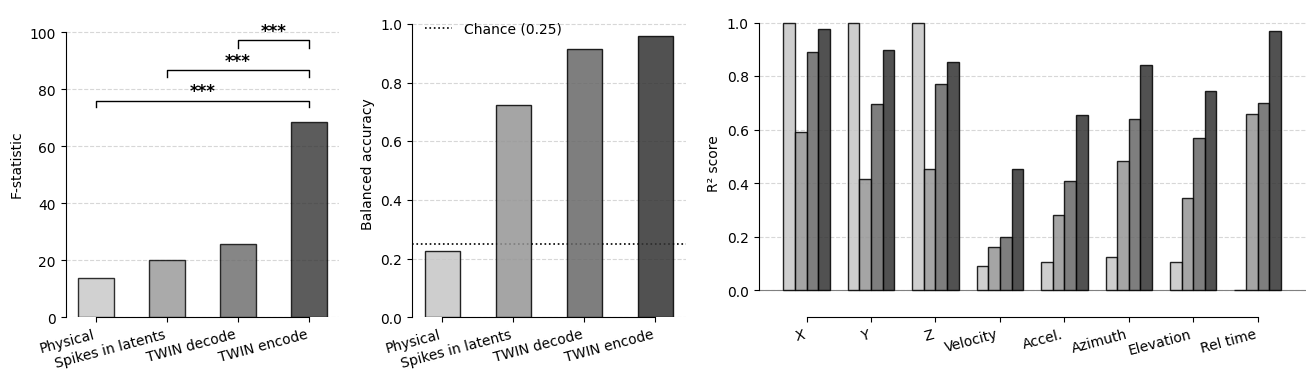

In [18]:
# 1. Setup the figure with the requested dimensions and layout
# Width: 4 + 4 + 8 = 16 inches, Height: 4 inches
fig, axes = plt.subplots(1, 3, figsize=(16, 4), gridspec_kw={'width_ratios': [4, 4, 8]})
# sns.set_theme(style="ticks")

# Define a clean, consistent color palette for the titles
palette = sns.color_palette("Greys", len(titles) + 1)[1:] # sns.color_palette("muted", len(titles))

# ==========================================
# COLUMN 1: F-STATISTIC COMPARISONS (AX 1)
# ==========================================
ax1 = axes[0]
target_title = "TWIN encode"
f_vals = [results_f_stats[t]['observed_f'] for t in titles]
target_idx = titles.index(target_title)

# Render gray bars as requested, highlighted by black outlines
bars1 = ax1.bar(titles, f_vals, color=palette, alpha=0.8, width=0.5, edgecolor='black', zorder=3)
ax1.set_ylabel("F-statistic")
# ax1.set_title("Manifold Topology Alignment", fontsize=12, fontweight='bold', pad=12)
ax1.set_xticks(range(len(titles)))
ax1.set_xticklabels(titles, rotation=15, ha='right')
ax1.grid(axis='y', linestyle='--', alpha=0.5, zorder=0)

# Stack significance brackets relative to 'TWIN encode'
max_f = max(f_vals)
y_pos = max_f * 1.08  
step = max_f * 0.15  
for i, title in enumerate(titles):
    if title == target_title:
        continue
    p_val = results_f_stats[title].get('p_val')
    if p_val is not None and stars_for_p(p_val):
        add_significance_bracket(ax1, x1=i, x2=target_idx, p=p_val, y=y_pos, height_frac=0.03)
        y_pos += step
ax1.set_ylim(bottom=0, top=y_pos + (max_f * 0.05))

# ==========================================
# COLUMN 2: ROUTE CLASSIFICATION (AX 2)
# ==========================================
ax2 = axes[1]
clf_accuracies = [results_latent_decode[t]['classification_balanced_accuracy'] for t in titles]

# Plot classification bars using our color palette
bars2 = ax2.bar(titles, clf_accuracies, color=palette, alpha=0.85, width=0.5, edgecolor='black', zorder=3)
ax2.set_ylabel("Balanced accuracy")
# ax2.set_title("Route Type Decoding", fontsize=12, fontweight='bold', pad=12)
ax2.set_xticks(range(len(titles)))
ax2.set_xticklabels(titles, rotation=15, ha='right')
ax2.grid(axis='y', linestyle='--', alpha=0.5, zorder=0)
ax2.set_ylim(0, 1.05)
# Chance line for 4-way classification (1/4 = 0.25)
ax2.axhline(0.25, color='k', linestyle=':', linewidth=1.2, label='Chance (0.25)', zorder=2)
ax2.legend(loc='best', frameon=False)

# # Add exact performance text labels above each bar
# for bar in bars2:
#     yval = bar.get_height()
#     ax2.text(bar.get_x() + bar.get_width()/2.0, yval + 0.02, f"{yval:.2f}", ha='center', va='bottom', fontsize=9)

# ==========================================
# COLUMN 3: KINEMATICS REGRESSION (AX 3)
# ==========================================
ax3 = axes[2]
# Dynamically extract continuous variables from the results dictionary keys
# ['X', 'Y', 'Z', 'Velocity', 'Accel.', 'Azimuth', 'Elevation', 'Rel time']
reg_vars = list(results_latent_decode[titles[0]]['regression_r2'].keys())
n_vars = len(reg_vars)
n_titles = len(titles)
# Grouped bar chart dimensions
bar_width = 0.18
group_width = bar_width * n_titles
indices = np.arange(n_vars)

# Plot grouped bars for each title model
for i, title in enumerate(titles):
    # Gather R2 values for this title across all decoded kinematic dimensions
    r2_vals = [results_latent_decode[title]['regression_r2'][var] for var in reg_vars]
    # Center the groups on the tick indices
    offsets = indices + (i - (n_titles - 1) / 2) * bar_width
    ax3.bar(offsets, r2_vals, width=bar_width, label=title, color=palette[i], alpha=0.85, edgecolor='black', zorder=3)
    
ax3.set_ylabel("R² score")
# ax3.set_title("Continuous Kinematics & Phase Decoding", fontsize=12, fontweight='bold', pad=12)
ax3.set_xticks(indices)
ax3.set_xticklabels(reg_vars, rotation=15, ha='right')
ax3.set_ylim(-0.1, 1.05)  # Allow negative values for poorly fit cross-validated R2
ax3.grid(axis='y', linestyle='--', alpha=0.5, zorder=0)
ax3.axhline(0, color='gray', linestyle='-', linewidth=0.8, zorder=2)
# ax3.legend(loc='upper right', frameon=True, facecolor='white', framealpha=0.9, fontsize=9)

# Apply spine styling across all three plots
for ax in axes:
    sns.despine(ax=ax, trim=True)

# plt.savefig(f"./out-figures/fig2-analyze-similarity-matrix-latent-decode.svg", dpi=300)
# plt.savefig(f"./out-figures/fig2-analyze-similarity-matrix-latent-decode.png", dpi=300)

# RSA on landmarks

In [19]:
def compute_similarity_matrix_landmark(all_features, metric='cosine', compute_matrix_flag=True):
    """
    Computes a pairwise similarity matrix across extracted discrete start/end landmark vectors.
    
    all_features: array of shape (L, D) (e.g., all_latents, all_xyz, or all_latents_pca3)
    """
    from scipy.spatial.distance import pdist, squareform

    # Find trajectory boundaries (where rel_time resets to 0)
    resets = np.where(all_rel_time == 0)[0]
    boundaries = np.append(resets, len(all_rel_time))
    landmarks = []
    metadata = []
    # helper helper to categorize environments
    def get_env(session_name):
        if "Dataset_1" in session_name or "Dataset_3" in session_name:
            return "Indoor"
        elif "Dataset_2" in session_name:
            return "Outdoor"
        return "Unknown"

    for i in range(len(boundaries) - 1):
        start, end = boundaries[i], boundaries[i+1]
        length = end - start    
        if MIN_LEN <= length <= MAX_LEN:
            # Determine environment
            session_name = all_session[start]
            env_type = get_env(session_name)
            if env_type == "Unknown":
                continue
            # Extract start and end feature vectors (1D vector of shape (D,))
            start_feat = all_features[start, :]
            end_feat = all_features[end - 1, :]
            
            # --- Classify Start Landmark ---
            if all_reward[start]:
                start_landmark = "Start@Rew"
            elif all_perch[start]:
                start_landmark = "Start@Per"
            else:
                start_landmark = "Start@Other"
            # --- Classify End Landmark ---
            if all_reward[end - 1]:
                end_landmark = "End@Rew"
            elif all_perch[end - 1]:
                end_landmark = "End@Per"
            else:
                end_landmark = "End@Other"

            # 1. Add Start Landmark entry
            landmarks.append(start_feat)
            metadata.append({
                'env': env_type,
                'landmark': start_landmark,
                'bat': all_bat[start],
                'session': session_name,
                's_cluster': all_cluster_session[start],
            })
            # 2. Add End Landmark entry
            landmarks.append(end_feat)
            metadata.append({
                'env': env_type,
                'landmark': end_landmark,
                'bat': all_bat[start],
                'session': session_name,
                's_cluster': all_cluster_session[start],
            })

    if len(landmarks) == 0:
        raise ValueError("No valid landmarks found with current filtering criteria.")

    # --- 2. Sorting & Hierarchy ---
    df_meta = pd.DataFrame(metadata)
    # Define categorical order for sorting
    df_meta['env'] = pd.Categorical(df_meta['env'], categories=['Indoor', 'Outdoor'])
    df_meta['landmark'] = pd.Categorical(
        df_meta['landmark'], 
        categories=["Start@Rew", "End@Rew", "Start@Per", "End@Per", "Start@Other", "End@Other"]
    )
    # Sort by the requested hierarchy: Env -> Landmark -> Bat -> Session -> S_Cluster
    df_meta = df_meta.sort_values(['env', 'landmark', 'bat', 'session', 's_cluster'])
    sorted_indices = df_meta.index.values

    # --- Matrix Generation Code ---
    # 1. Sort the extracted landmark vectors
    sorted_landmarks = [landmarks[i] for i in sorted_indices]
    sorted_landmarks_arr = np.array(sorted_landmarks) # Shape: (Num_Landmarks, D)
    num_landmarks = len(sorted_landmarks)
    similarity_matrix = np.zeros((num_landmarks, num_landmarks))
    # 2. Populate the pairwise similarity matrix (1 - Distance)
    if compute_matrix_flag:
        # Utilizing fast scipy pdist implementation for flat vectors
        dist_vector = pdist(sorted_landmarks_arr, metric=metric)
        dist_matrix = squareform(dist_vector)
        similarity_matrix = 1.0 - dist_matrix
        
    return sorted_landmarks, similarity_matrix, df_meta


def compute_f_stats_and_null_landmark(
    sim_mat_list, 
    df_meta, 
    titles, 
    target_title="TWIN encode", 
    env='Indoor', 
    landmarks=["Start@Rew", "End@Rew", "Start@Per", "End@Per"], 
    n_permutations=1000
):
    """
    Computes observed F-statistics and null distribution differences via synchronous 
    matrix-swapping permutations, specifically comparing landmark categories.
    """
    # Step 1: Filter Indices & Prepare Distance Matrices
    # Filter indices based on environment and matching landmark types
    mask = (df_meta['env'] == env).values & df_meta['landmark'].isin(landmarks).values
    labels = np.array(df_meta['landmark'].values[mask], copy=True)  # Ensure clean NumPy array for stability
    n_samples = len(labels)
    obs_f_dict = {}
    dist_mats = {}
    # Compute observed F-statistics and convert similarity to distance
    for sim_mat, title in zip(sim_mat_list, titles):
        mat = sim_mat[mask][:, mask]
        dist_mat = np.ascontiguousarray(1 - mat)
        dist_mats[title] = dist_mat
        obs_f_dict[title] = calc_f_stat(dist_mat, labels)
    # Get target reference metrics
    target_obs_f = obs_f_dict[target_title]
    target_dist_mat = dist_mats[target_title]
    
    # Step 2: Permutation Distributions and Differences
    results = {}
    for title in titles:
        obs_f = obs_f_dict[title]
        if title == target_title:
            # Target comparison metrics are assigned None/empty values
            results[title] = {
                "observed_f": obs_f,
                "obs_diff": None,
                "null_diffs": np.zeros(n_permutations),
                "p_val": None
            }
            continue
            
        # Initialize calculations comparing this title with target_title
        current_dist_mat = dist_mats[title]
        obs_diff = obs_f - target_obs_f
        null_diffs = np.zeros(n_permutations)
        # Matrix swapping permutations
        for p in range(n_permutations):
            # Mask to randomly select rows/columns to swap identities between matrices
            swap_mask = np.random.rand(n_samples) > 0.5
            perm_current = current_dist_mat.copy()
            perm_target = target_dist_mat.copy()
            # Synchronously swap rows and columns between current and target matrices
            perm_current[swap_mask, :] = target_dist_mat[swap_mask, :]
            perm_target[swap_mask, :] = current_dist_mat[swap_mask, :]
            perm_current[:, swap_mask] = target_dist_mat[:, swap_mask]
            perm_target[:, swap_mask] = current_dist_mat[:, swap_mask]
            # Compute simulated difference under the null hypothesis
            null_diffs[p] = calc_f_stat(perm_current, labels) - calc_f_stat(perm_target, labels)
        # Calculate two-tailed p-value
        p_val = np.sum(np.abs(null_diffs) >= np.abs(obs_diff)) / n_permutations
        results[title] = {
            "observed_f": obs_f,
            "obs_diff": np.abs(obs_diff),
            "null_diffs": np.abs(null_diffs),
            "p_val": p_val
        }
        
    return results

In [20]:
land_xyz, sim_mat_land_xyz, df_meta_land_xyz = compute_similarity_matrix_landmark(all_xyz, metric='euclidean')
land_latents, sim_mat_land_latents, _ = compute_similarity_matrix_landmark(all_latents, metric='cosine')
land_latents_pca3, _, _ = compute_similarity_matrix_landmark(all_latents_pca3, metric='cosine')

land_list = [land_xyz, land_latents_pca3]
sim_mat_land_list = [sim_mat_land_xyz, sim_mat_land_latents]
land_titles = ["Physical", "TWIN encode"]
land_axislabels = [['X', 'Y'], ['PC 1', 'PC 2']]

# results_f_stats_land = compute_f_stats_and_null_landmark(sim_mat_land_list, df_meta_land_xyz, land_titles, landmarks=["Start@Rew", "End@Rew"], )

/tmp/ipykernel_1996/3186958624.py:73: UserWarning: The following kwargs were not used by contour: 'rasterized'
  ax.contourf(xx, yy, Z, alpha=0.1, cmap='Set1', zorder=0, rasterized=True)
/tmp/ipykernel_1996/3186958624.py:74: UserWarning: The following kwargs were not used by contour: 'rasterized'
  ax.contour(xx, yy, Z, colors='k', linewidths=0.75, linestyles='--', zorder=1, rasterized=True)
/tmp/ipykernel_1996/3186958624.py:73: UserWarning: The following kwargs were not used by contour: 'rasterized'
  ax.contourf(xx, yy, Z, alpha=0.1, cmap='Set1', zorder=0, rasterized=True)
/tmp/ipykernel_1996/3186958624.py:74: UserWarning: The following kwargs were not used by contour: 'rasterized'
  ax.contour(xx, yy, Z, colors='k', linewidths=0.75, linestyles='--', zorder=1, rasterized=True)


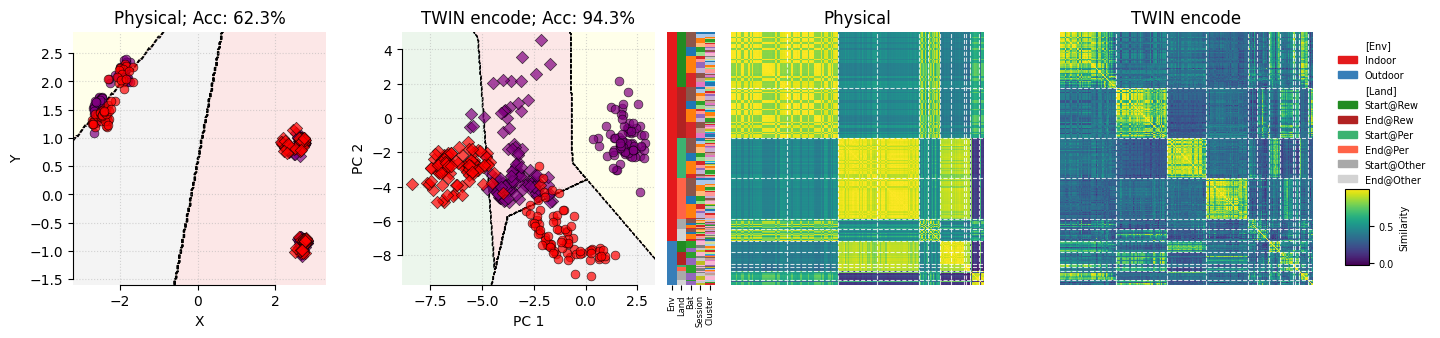

In [21]:
# --- Build the shared Sidebar DataFrame ---
env_colors = get_color_sidebar(df_meta_land_xyz, 'env', "Set1").tolist()
land_colors = df_meta_land_xyz['landmark'].map(landmark_palette()).tolist()
bat_colors = df_meta_land_xyz['bat'].map(bat_palette()).tolist()
session_colors = get_color_sidebar(df_meta_land_xyz, 'session', "tab20").tolist()
s_cluster_colors = get_color_sidebar(df_meta_land_xyz, 's_cluster', "tab20").tolist()
sidebar_df = pd.DataFrame({
    "Env": env_colors,
    "Land": land_colors,
    "Bat": bat_colors,
    "Session": session_colors,
    "Cluster": s_cluster_colors,
}, index=df_meta_land_xyz.index)
sidebar_rgb = colors_to_rgb_array(sidebar_df)

# Identify group boundary indices for the white dividing lines
# Since the dataframe is sorted, we find where the landmark category changes
landmark_changes = np.where(df_meta_land_xyz['landmark'].values[:-1] != df_meta_land_xyz['landmark'].values[1:])[0]
landmark_boundaries = landmark_changes + 1

# 3. Create the Main Subplots and Heatmaps
fig, axes = plt.subplots(1, 4, figsize=(16, 4), gridspec_kw={'width_ratios': [4, 4, 4, 4]})
# Increase the horizontal spacing between subplots specifically to make room for the sidebar
plt.subplots_adjust(wspace=0.3)

# =============================================================================
# scatter plot of landmarks
# Map styling rules to extract and plot coordinate data (mapping to class indices for SVM)
plot_configs = [
    ("Start@Rew", "purple", "D", "Start@Rew", 0),
    ("End@Rew",   "red",   "D", "End@Rew",   1),
    ("Start@Per", "purple", "o", "Start@Per", 2),
    ("End@Per",    "red",   "o", "End@Per",   3)
]
# Filter landmarks and metadata to include only Indoor flights
is_indoor = (df_meta_land_xyz['env'] == 'Indoor').values
# Plot 2D scatter plots using the coordinate datasets inside land_list
for i in range(2):
    ax = axes[i]
    ax.set_box_aspect(1)  # Force the axes to be square
    
    # Convert list of coordinates to a clean (Num_Landmarks, D) numpy array
    coords_arr = np.array(land_list[i])
    # Filter to get indoor coordinates and labels
    indoor_coords = coords_arr[is_indoor][:, :2]  # We only classify on the 2D plane (PC1, PC2)
    indoor_labels = df_meta_land_xyz['landmark'].values[is_indoor]
    # --- Step 1: Gather and Label Data for SVM ---
    X_list = []
    y_list = []
    for key, color, marker, label, class_idx in plot_configs:
        label_mask = (indoor_labels == key)
        if np.any(label_mask):
            X_list.append(indoor_coords[label_mask])
            y_list.append(np.full(np.sum(label_mask), class_idx))
    if len(X_list) > 0:
        X = np.vstack(X_list)
        y = np.concatenate(y_list)
        # --- Step 2: Fit Linear SVM & Calculate Accuracy ---
        clf = SVC(kernel='linear', C=1.0)
        clf.fit(X, y)
        y_pred = clf.predict(X)
        accuracy = accuracy_score(y, y_pred) * 100
        # --- Step 3: Plot Decision Boundaries ---
        # Generate dynamic coordinate range for the local grid
        x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
        y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
        xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.04),
                             np.arange(y_min, y_max, 0.04))
        # Predict classes across the spatial meshgrid
        Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])
        Z = Z.reshape(xx.shape)
        # Draw background color regions and boundary lines
        ax.contourf(xx, yy, Z, alpha=0.1, cmap='Set1', zorder=0)
        ax.contour(xx, yy, Z, colors='k', linewidths=0.75, linestyles='--', zorder=1)
        
        title_suffix = f"; Acc: {accuracy:.1f}%"
    else:
        title_suffix = ""

    # --- Step 4: Scatter Plot Data Points ---
    for key, color, marker, label, class_idx in plot_configs:
        label_mask = (indoor_labels == key)
        if not np.any(label_mask):
            continue
        data_arr = indoor_coords[label_mask]
        ax.scatter(
            data_arr[:, 0], data_arr[:, 1], 
            c=color, marker=marker, alpha=0.7, 
            edgecolors='k', linewidths=0.5, s=40, zorder=2, rasterized=True
        )
    ax.set_xlabel(land_axislabels[i][0])
    ax.set_ylabel(land_axislabels[i][1])
    ax.set_title(f"{land_titles[i]}{title_suffix}")
    ax.grid(True, linestyle=":", alpha=0.5)

# =============================================================================
# 3. Plot the Heatmaps (Last Two Axes: axes[2] and axes[3])
num_cols = len(land_list)
for i in range(num_cols):
    ax = axes[2+i]
    sim_matrix = sim_mat_land_list[i]
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlabel('Landmarks (sorted)')
    # Calculate vmin and vmax excluding diagonal self-similarity values
    off_diagonal_vals = sim_matrix[~np.eye(sim_matrix.shape[0], dtype=bool)]
    v_min = np.min(off_diagonal_vals)
    v_max = np.max(off_diagonal_vals)
    # Draw the main similarity matrix
    im = sns.heatmap(
        sim_matrix, ax=ax, cmap="viridis", cbar=False,
        vmin=v_min, vmax=v_max, xticklabels=False, yticklabels=False, square=True, rasterized=True
    )
    # Add white dashed boundary lines between different landmark blocks
    for boundary in landmark_boundaries:
        ax.axhline(y=boundary, color='white', linestyle='--', linewidth=0.8, alpha=0.8)
        ax.axvline(x=boundary, color='white', linestyle='--', linewidth=0.8, alpha=0.8)
    ax.set_title(land_titles[i])
plt.draw()  # Force geometry calculations to acquire accurate bounding box positions

# 4. Inject the Left Sidebar (First Axis Only)
first_heatmap_ax = axes[2]
heatmap_pos = first_heatmap_ax.get_position()
sidebar_width = 0.03
sidebar_padding = 0.01
sidebar_ax = fig.add_axes([
    heatmap_pos.x0 - sidebar_width - sidebar_padding, 
    heatmap_pos.y0, 
    sidebar_width, 
    heatmap_pos.height
])
sidebar_ax.imshow(sidebar_rgb, aspect='auto', interpolation='nearest')
sidebar_ax.set_xticks(range(len(sidebar_df.columns)))
sidebar_ax.set_xticklabels(sidebar_df.columns, rotation=90, fontsize=6)
sidebar_ax.set_yticks([])
sidebar_ax.spines[:].set_visible(False)
# 5. Position the Shared Colorbar (Last Axis Only)
last_heatmap_ax = axes[3]
last_heatmap_pos = last_heatmap_ax.get_position()
cbar_width = 0.015
cbar_ax = fig.add_axes([
    last_heatmap_pos.x1 + 0.02, 
    last_heatmap_pos.y0 + 0.05, 
    cbar_width, 
    last_heatmap_pos.height * 0.3
])
cbar = fig.colorbar(last_heatmap_ax.collections[0], cax=cbar_ax)
cbar.set_label("Similarity", fontsize=7)
cbar.ax.tick_params(labelsize=7)
# 6. Generate and Position Legend (Last Axis Only)
# Create unique color mappings for 'bat' palette to show in legend
bat_unique_keys = df_meta_land_xyz['bat'].unique()
bat_colors = sns.color_palette("tab10", len(bat_unique_keys))
bat_dict = dict(zip(bat_unique_keys, bat_colors))
env_h = get_legend_handles(df_meta_land_xyz, 'env', "Set1", "Env")
type_h = get_legend_handles_from_dict(landmark_palette(), "Land")
bat_h = get_legend_handles_from_dict(bat_dict, "Bat")
# Combine the handles
all_handles = env_h + type_h # + bat_h
fig.legend(
    handles=all_handles, 
    loc='upper left',
    bbox_to_anchor=(last_heatmap_pos.x1 + 0.01, last_heatmap_pos.y1),
    ncol=1, 
    frameon=False, 
    fontsize=7
)

sns.despine(ax=axes[0], trim=True)
sns.despine(ax=axes[1], trim=True)
# plt.savefig(f"./out-figures/fig2-RSA-on-landmarks.svg", dpi=300)
# plt.savefig(f"./out-figures/fig2-RSA-on-landmarks.png", dpi=300)

# Dynamical analysis

In [17]:
def compute_eigen_feature(lambdas, power, data_type = 'neuronal'):
    # Define a high-resolution grid over the complex plane to capture subtle frequency shifts
    # Expanded slightly beyond 1.2 to fully capture the slow-decaying baseline dynamics
    real_bins = np.linspace(-1.2, 1.2, 20)
    imag_bins = np.linspace(-1.2, 1.2, 20)
    # Create a 2D density distribution weighted explicitly by mode power
    # This ensures highly energetic rhythms dominate the temporal signature
    H, x_edges, y_edges = np.histogram2d(
        np.real(lambdas), 
        np.imag(lambdas), 
        bins=[real_bins, imag_bins], 
        weights=power,
    )
    # IF NEURONAL: Suppress the 0.0 Hz imaginary axis line entirely
    if data_type == 'neuronal':
        # Find the bin index matching Imaginary = 0.0
        # y_edges corresponds to the imaginary axis bins
        imag_centers = (y_edges[:-1] + y_edges[1:]) / 2.0
        zero_imag_idx = np.argmin(np.abs(imag_centers))
        # Zero out the entire real-axis row where imaginary frequency is 0
        H[:, zero_imag_idx] = 0.0
    
    # Flatten the 2D spectral map into a 1D temporal feature vector
    feat = H.flatten()
    # Normalize the vector to unit norm
    feat /= (np.linalg.norm(feat) + 1e-12)

    return feat

def compute_similarity_matrix_DMD(all_features, metric='cosine', compute_matrix_flag=True, hh = 6, top_mode_index=1):
    """
    all_features: can be all_latents: (L, 32), all_xyz: (L, 3), all_latents_pca3: (L, 3)
    hh: argument for FlightDMD()
    top_mode_index: select the mode index for computing similarity
    """
    # Find trajectory boundaries (where rel_time resets to 0)
    resets = np.where(all_rel_time == 0)[0]
    boundaries = np.append(resets, len(all_rel_time))
    trajectories = []
    metadata = []
    for i in range(len(boundaries) - 1):
        start, end = boundaries[i], boundaries[i+1]
        length = end - start    
        if MIN_LEN <= length <= MAX_LEN:
            # Extract latent slice
            traj_latents = all_features[start:end] # all_latents: (L, 32); all_latents_pca3: (L, 3) 

            # Determine Flight Type
            is_rew = all_reward[start:end]
            is_per = all_perch[start:end]
            if is_rew[0] and is_per[-1]: f_type = "Rew->Per"
            elif is_per[0] and is_rew[-1]: f_type = "Per->Rew"
            elif is_rew[0] and is_rew[-1]: f_type = "Rew->Rew"
            elif is_per[0] and is_per[-1]: f_type = "Per->Per"
            else: f_type = "Other"

            # trajectories.append(resampled_latent.flatten()) # Flatten to (1600,)
            trajectories.append(traj_latents) 
            metadata.append({
                'env': get_env(all_session[start]),
                'f_type': f_type,
                'bat': all_bat[start],
                'session': all_session[start],
                's_cluster': all_cluster_session[start],
            })
    # --- 2. Sorting & Hierarchy ---
    df_meta = pd.DataFrame(metadata)
    # Define categorical order for sorting
    df_meta['env'] = pd.Categorical(df_meta['env'], categories=['Indoor', 'Outdoor'])
    df_meta['f_type'] = pd.Categorical(df_meta['f_type'], 
                                    categories=["Rew->Rew", "Rew->Per", "Per->Rew", "Per->Per", "Other"])
    # Sort by the hierarchy: Env -> Flight Type -> Bat -> Session
    df_meta = df_meta.sort_values(['env', 'f_type', 'bat', 'session', 's_cluster'])
    sorted_indices = df_meta.index.values

    # --- Matrix Generation Code for DMD mode
    # 1. Sort the trajectories
    sorted_trajectories = [trajectories[i] for i in sorted_indices]
    num_trajectories = len(sorted_trajectories)
    similarity_matrix = np.zeros((num_trajectories, num_trajectories))
    # 2. Populate the pairwise similarity matrix (1 - Distance)
    if compute_matrix_flag:
        # compute the DMD mode
        sorted_dmd_mode = []
        sorted_eigen_feature = []
        for flight_latents in sorted_trajectories:
            # If use all_true_spike (shape: 8332 by 266): 
            # Select all rows, but only columns (neurons) that are NOT completely NaN
            flight_latents = flight_latents[:, ~np.isnan(flight_latents).all(axis=0)] # shape: (num_time_points, num_features)
            flight_latents = flight_latents.T # DMD works for the data with a shape of (num_feature, num_time_points)
            # DMD
            flight_dmd = FlightDMD(use_stacking=True, h=hh)
            flight_dmd.fit(flight_latents)    
            modes = flight_dmd.dmd_modes
            power = flight_dmd.power 
            top_indices = np.argsort(power)[::-1][top_mode_index]
            primary_mode = np.real(modes[:, top_indices])
            sorted_dmd_mode.append(primary_mode)
            sorted_eigen_feature.append(compute_eigen_feature(flight_dmd.eigenvalues, flight_dmd.power))
        # Utilizing fast scipy pdist implementation for flat vectors
        sorted_dmd_mode = np.array(sorted_dmd_mode) # Shape: (num_trajectories, D)
        sorted_eigen_feature = np.array(sorted_eigen_feature)

        # dist_vector = pdist(sorted_dmd_mode, metric=metric)
        # dist_matrix = squareform(dist_vector)
        # similarity_matrix = 1.0 - dist_matrix
        sorted_dmd_mode /= (np.linalg.norm(sorted_dmd_mode, axis=1, keepdims=True) + 1e-12)
        similarity_matrix = np.abs(sorted_dmd_mode @ sorted_dmd_mode.T) # Note that there may be sign flips for the DMD mode
        similarity_matrix_eigen = sorted_eigen_feature @ sorted_eigen_feature.T

    return sorted_trajectories, similarity_matrix, similarity_matrix_eigen, df_meta

def extract_route_similarities(sim_mat, meta_df, exclude_types=['Other']):
    """
    Extracts off-diagonal pairwise similarity values categorized as
    'Within Route' or 'Between Route', ignoring specified flight types.
    """
    # Mask out excluded flight types (e.g., 'Other')
    valid_mask = ~meta_df['f_type'].isin(exclude_types).to_numpy()
    # Filter metadata and matrix
    sub_df = meta_df[valid_mask].reset_index(drop=True)
    sub_mat = sim_mat[np.ix_(valid_mask, valid_mask)]
    
    f_types = sub_df['f_type'].values
    n = len(f_types)
    # Get upper triangle indices (excluding self-similarity diagonal)
    triu_i, triu_j = np.triu_indices(n, k=1)
    within_vals = []
    between_vals = []
    for i, j in zip(triu_i, triu_j):
        val = sub_mat[i, j]
        if f_types[i] == f_types[j]:
            within_vals.append(val)
        else:
            between_vals.append(val)  
            
    return np.array(within_vals), np.array(between_vals)

def compute_similarity_matrix_DMD_motif(all_features, metric='cosine', compute_matrix_flag=True, hh=6, top_mode_index=1):
    """
    all_features: can be all_latents: (L, 32), all_xyz: (L, 3), all_latents_pca3: (L, 3)
    hh: argument for FlightDMD()
    top_mode_index: select the mode index for computing similarity
    """
    # Find trajectory boundaries (where rel_time resets to 0)
    resets = np.where(all_rel_time == 0)[0]
    boundaries = np.append(resets, len(all_rel_time))
    trajectories = []  # Acts as 'motifs'
    metadata = []
    
    for i in range(len(boundaries) - 1):
        start, end = boundaries[i], boundaries[i+1]
        length = end - start    
        if MIN_LEN <= length <= MAX_LEN:
            # Extract latent slice
            traj_latents = all_features[start:end]
            # Determine original Flight Type
            is_rew = all_reward[start:end]
            is_per = all_perch[start:end]
            common_meta = {'env': get_env(all_session[start]), 'bat': all_bat[start],
                'session': all_session[start], 's_cluster': all_cluster_session[start],}
            if is_rew[0] and is_per[-1]:
                # Complete trajectory = Motif
                trajectories.append(traj_latents)
                metadata.append({**common_meta, 'motif': 'Away', 'f_type': 'Rew->Per'})
            elif is_per[0] and is_rew[-1]:
                # Complete trajectory = Motif
                trajectories.append(traj_latents)
                metadata.append({**common_meta, 'motif': 'Toward', 'f_type': 'Per->Rew'})
            elif is_rew[0] and is_rew[-1]:
                # Split Rew->Rew into two motifs at midpoint
                mid = length // 2
                # First half: Away (Rew->Half)
                trajectories.append(traj_latents[:mid])
                metadata.append({**common_meta, 'motif': 'Away', 'f_type': 'Rew->Half'})
                # Second half: Toward (Half->Rew)
                trajectories.append(traj_latents[mid:])
                metadata.append({**common_meta, 'motif': 'Toward', 'f_type': 'Half->Rew'})
            else:
                # Per->Per or Other -> classified as 'Other'
                trajectories.append(traj_latents)
                metadata.append({**common_meta, 'motif': 'Other', 'f_type': 'Other'})

    # --- 2. Sorting & Hierarchy ---
    df_meta = pd.DataFrame(metadata)
    # Define categorical order for sorting
    df_meta['env'] = pd.Categorical(df_meta['env'], categories=['Indoor', 'Outdoor'])
    df_meta['motif'] = pd.Categorical(df_meta['motif'], categories=['Away', 'Toward', 'Other'])
    df_meta['f_type'] = pd.Categorical(df_meta['f_type'], 
        categories=['Rew->Per', 'Rew->Half', 'Per->Rew', 'Half->Rew', 'Other'])
    # Sort by hierarchy: Env -> Motif -> Flight Type -> Bat -> Session -> Cluster
    df_meta = df_meta.sort_values(['env', 'motif', 'f_type', 'bat', 'session', 's_cluster'])
    sorted_indices = df_meta.index.values

    # --- Matrix Generation Code for DMD mode ---
    # 1. Sort the trajectories (motifs)
    sorted_trajectories = [trajectories[i] for i in sorted_indices]
    num_trajectories = len(sorted_trajectories)
    similarity_matrix = np.zeros((num_trajectories, num_trajectories))
    similarity_matrix_eigen = np.zeros((num_trajectories, num_trajectories))
    # 2. Populate the pairwise similarity matrix
    if compute_matrix_flag:
        sorted_dmd_mode = []
        sorted_eigen_feature = []
        for flight_latents in sorted_trajectories:
            flight_latents = flight_latents[:, ~np.isnan(flight_latents).all(axis=0)]
            flight_latents = flight_latents.T  # Shape: (features, time_points)
            # DMD
            flight_dmd = FlightDMD(use_stacking=True, h=hh)
            flight_dmd.fit(flight_latents)    
            modes = flight_dmd.dmd_modes
            power = flight_dmd.power 
            top_indices = np.argsort(power)[::-1][top_mode_index]
            primary_mode = np.real(modes[:, top_indices])
            sorted_dmd_mode.append(primary_mode)
            sorted_eigen_feature.append(compute_eigen_feature(flight_dmd.eigenvalues, flight_dmd.power))
        sorted_dmd_mode = np.array(sorted_dmd_mode)
        sorted_eigen_feature = np.array(sorted_eigen_feature)
        sorted_dmd_mode /= (np.linalg.norm(sorted_dmd_mode, axis=1, keepdims=True) + 1e-12)
        similarity_matrix = np.abs(sorted_dmd_mode @ sorted_dmd_mode.T)
        similarity_matrix_eigen = sorted_eigen_feature @ sorted_eigen_feature.T

    return sorted_trajectories, similarity_matrix, similarity_matrix_eigen, df_meta

def extract_motif_similarities(sim_mat, meta_df, exclude_types=['Other']):
    """
    Extracts off-diagonal pairwise similarity values categorized as
    'Within Motif' or 'Between Motif', ignoring specified motif types.
    """
    # Mask out excluded flight types (e.g., 'Other')
    valid_mask = ~meta_df['motif'].isin(exclude_types).to_numpy()
    # Filter metadata and matrix
    sub_df = meta_df[valid_mask].reset_index(drop=True)
    sub_mat = sim_mat[np.ix_(valid_mask, valid_mask)]
    
    f_types = sub_df['motif'].values
    n = len(f_types)
    # Get upper triangle indices (excluding self-similarity diagonal)
    triu_i, triu_j = np.triu_indices(n, k=1)
    within_vals = []
    between_vals = []
    for i, j in zip(triu_i, triu_j):
        val = sub_mat[i, j]
        if f_types[i] == f_types[j]:
            within_vals.append(val)
        else:
            between_vals.append(val)  
            
    return np.array(within_vals), np.array(between_vals)

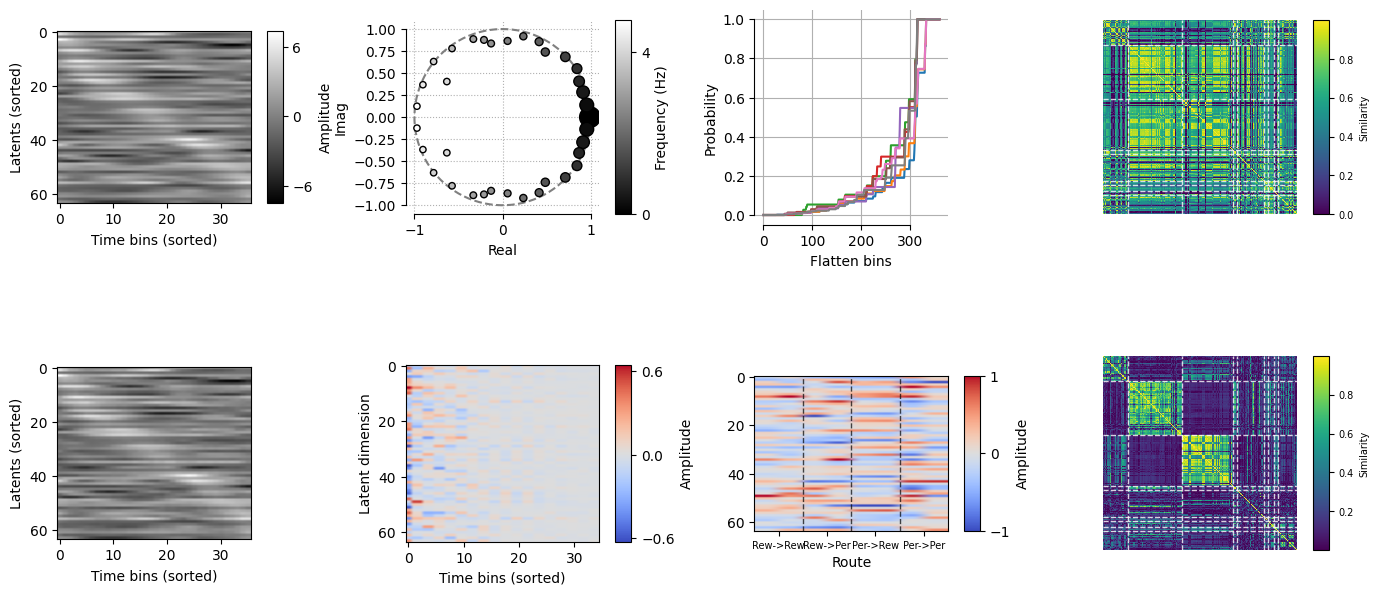

In [15]:
sorted_trajectories_dmd, sim_mat_dmdmode, sim_mat_dmdeigen, df_meta_dmd = compute_similarity_matrix_DMD(all_latents, metric='cosine')
hh = 6
top_mode_index = 1
fig, axes = plt.subplots(2, 4, figsize=(16, 8), gridspec_kw={'width_ratios': [4, 4, 4, 4], 'wspace': 0.8})

# for the first 2 columns, we show the eigenvalues and DMD mode for one example flight trace
task, ind = 'Rew->Rew', 0
mask = (df_meta_dmd['env'] == 'Indoor') & (df_meta_dmd['f_type'] == task)
raw_data = sorted_trajectories_dmd[np.where(mask.to_numpy())[0][ind]].T  # should be in the shape of (num_feature, num_time_points) for FlightDMD
flight_dmd = FlightDMD(use_stacking=True, h=hh)
flight_dmd.fit(raw_data)

# raw and reconstructed flights in the latent space
ax = axes[0,0]
time_bins = flight_dmd.reconstructed_data.shape[1]
data = flight_dmd.data[:, :time_bins] # due to shift_stacking, it drops its last h-1 time points
vmin = np.min(np.concatenate((data, flight_dmd.reconstructed_data)))
vmax = np.max(np.concatenate((data, flight_dmd.reconstructed_data)))
peak_times = []
for cc in range(len(data)):
    peak_times.append(np.argmax(data[cc]))
peak_times = np.array(peak_times)
sort_order = np.argsort(peak_times)
im = ax.imshow(data[sort_order, :], cmap='gray', vmin=vmin, vmax=vmax)
ax.set_xlabel("Time bins (sorted)")
ax.set_ylabel('Latents (sorted)')
ax.set_aspect(0.5)
pos = ax.get_position()  # [x0, y0, width, height]
cax = fig.add_axes([pos.x1 + 0.01, pos.y0, 0.01, pos.height])
cbar = fig.colorbar(im, cax=cax, ticks=[-6, 0 ,6])
cbar.set_label('Amplitude')

ax = axes[1,0]
im = ax.imshow(flight_dmd.reconstructed_data[sort_order, :], cmap='gray', vmin=vmin, vmax=vmax)
ax.set_xlabel("Time bins (sorted)")
ax.set_ylabel('Latents (sorted)')
ax.set_aspect(0.5)

# eigenvalues
ax = axes[0,1]
# Subplot A: Unit Circle Domain
theta = np.linspace(0, 2*np.pi, 100)
ax.plot(np.cos(theta), np.sin(theta), color='gray', linestyle='--')
# Scatter eigenvalues scaled by log-power amplitudes
scatter_size = 20 + 200 * (flight_dmd.power / np.max(flight_dmd.power))
sc = ax.scatter(np.real(flight_dmd.eigenvalues), np.imag(flight_dmd.eigenvalues), 
                        s=scatter_size, c=flight_dmd.frequencies, cmap='gray', edgecolors='k', zorder=3)
ax.set_xlabel("Real")
ax.set_ylabel("Imag")
# ax.set_yticks([-1, 0, 1])
ax.grid(True, linestyle=':')
ax.set_aspect('equal')
# fig.colorbar(sc, ax=ax, label='Frequency (Hz)', shrink=0.6)
sns.despine(ax=ax, trim=True)
# ax.set_aspect(0.5)
pos = ax.get_position()  # [x0, y0, width, height]
cax = fig.add_axes([pos.x1 + 0.01, pos.y0, 0.01, pos.height])
cbar = fig.colorbar(sc, cax=cax, ticks=[0 , 4])
cbar.set_label('Frequency (Hz)')

# Real part of the top spatial modes
ax = axes[1,1]
modes = np.real(flight_dmd.dmd_modes[:flight_dmd.n_features, np.argsort(flight_dmd.power)[::-1]])
# modes /= (np.linalg.norm(modes, axis=0, keepdims=True) + 1e-12)
im = ax.imshow(modes, aspect='auto', cmap='coolwarm')
ax.set_xlabel("Time bins (sorted)")
ax.set_ylabel('Latent dimension')
ax.set_aspect(0.5)
# fig.colorbar(im, ax=ax, label='Amplitude', shrink=0.6)
# ax.set_box_aspect(0.98)
pos = ax.get_position()  # [x0, y0, width, height]
cax = fig.add_axes([pos.x1 + 0.01, pos.y0, 0.01, pos.height])
cbar = fig.colorbar(im, cax=cax, ticks=[-0.6, 0 , 0.6])
cbar.set_label('Amplitude')

# ==============================================================================
# for the third column, we show the DMD mode (use the one with second largest power) for different routes, each route with 2 flights
tasks = ['Rew->Rew', 'Rew->Per', 'Per->Rew', 'Per->Per']
inds = [0, 2]

ax = axes[0, 2]
eigen_features = []
for task in tasks:
    task_eigens = []  # Temporarily store the two modes for this task
    for ii, ind in enumerate(inds):
        mask = (df_meta_dmd['env'] == 'Indoor') & (df_meta_dmd['f_type'] == task)
        raw_data = sorted_trajectories_dmd[np.where(mask.to_numpy())[0][ind]].T # should be in the shape of (num_feature, num_time_points) for FlightDMD
        flight_dmd = FlightDMD(use_stacking=True, h=hh)
        flight_dmd.fit(raw_data)
        task_eigens.append(compute_eigen_feature(flight_dmd.eigenvalues, flight_dmd.power))
    eigen_features.extend(task_eigens)
eigen_features = np.array(eigen_features) # shape: (n_samples, n_features)
eigen_features = np.cumsum(eigen_features, axis=1)
eigen_features = eigen_features/eigen_features[:, -1][:,None]
for ii in range(len(eigen_features)):
    ax.plot(eigen_features[ii])
ax.set_xlabel('Flatten bins')
ax.set_ylabel('Probability')
ax.grid(True)
sns.despine(ax=ax, trim=True)
ax.set_aspect(400)

ax = axes[1, 2]
primary_modes = []
for task in tasks:
    task_modes = []  # Temporarily store the two modes for this task
    for ii, ind in enumerate(inds):
        mask = (df_meta_dmd['env'] == 'Indoor') & (df_meta_dmd['f_type'] == task)
        raw_data = sorted_trajectories_dmd[np.where(mask.to_numpy())[0][ind]].T # should be in the shape of (num_feature, num_time_points) for FlightDMD
        flight_dmd = FlightDMD(use_stacking=True, h=hh)
        flight_dmd.fit(raw_data)
        modes = flight_dmd.dmd_modes[:flight_dmd.n_features,]
        power = flight_dmd.power 
        top_indices = np.argsort(power)[::-1][top_mode_index]
        primary_mode = np.real(modes[:, top_indices])
        # Align sign of the second flight to match the first flight
        if ii == 1:
            if np.dot(primary_mode, task_modes[0]) < 0:
                primary_mode = -primary_mode
        task_modes.append(primary_mode)
    primary_modes.extend(task_modes)
primary_modes = np.array(primary_modes).T # shape: (n_features, n_samples)
# primary_modes /= (np.linalg.norm(primary_modes, axis=0, keepdims=True) + 1e-12)
primary_modes /= np.max(np.abs(primary_modes), axis=0, keepdims=True)
im = ax.imshow(primary_modes, aspect='auto', cmap='coolwarm')
# 1. Generate and set paired labels (e.g., "Rew->Rew\nF_0")
labels = [f"{task}" for task in tasks]
ax.set_xticks([0.5, 2.5, 4.5, 6.5])
ax.set_xticklabels(labels, fontsize=7)
ax.set_xlabel("Route")
# 2. Add vertical lines at the boundaries between tasks
for x in [1.5, 3.5, 5.5]:
    ax.axvline(x, color='black', linestyle='--', linewidth=1.0, alpha=0.7)
# fig.colorbar(im, ax=ax, label='Amplitude', shrink=0.6, pad=0.04)
# ax.set_box_aspect(1.2)
ax.set_aspect(0.1)
pos = ax.get_position()  # [x0, y0, width, height]
cax = fig.add_axes([pos.x1 + 0.01, pos.y0, 0.01, pos.height])
cbar = fig.colorbar(im, cax=cax, ticks=[-1, 0 , 1])
cbar.set_label('Amplitude')

# ==============================================================================
# the fourth column shows the spatial subspace alignment
ax = axes[0, 3]
df_meta = df_meta_dmd.copy()
# --- Calculate Route Boundaries ---
f_type_series = df_meta['f_type'].values
route_boundaries = np.where(f_type_series[:-1] != f_type_series[1:])[0] + 1
sim_matrix = np.copy(sim_mat_dmdeigen)
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel('Flights (sorted)')
# Calculate vmin and vmax excluding the diagonal values
off_diagonal_vals = sim_matrix[~np.eye(sim_matrix.shape[0], dtype=bool)]
v_min = np.min(off_diagonal_vals)
v_max = np.max(off_diagonal_vals)
# Draw the main similarity matrix (cbar=False for ALL to keep shapes identical)
im = sns.heatmap(
    sim_matrix, ax=ax, cmap="viridis", cbar=False,
    vmin=v_min, vmax=v_max, xticklabels=False, yticklabels=False, square=True, rasterized=True
)
# Add the white dashed boundary lines across rows and columns
for boundary in route_boundaries:
    ax.axhline(y=boundary, color='white', linestyle='--', linewidth=1.0, alpha=0.8)
    ax.axvline(x=boundary, color='white', linestyle='--', linewidth=1.0, alpha=0.8)
# ax.set_title(titles[i])
plt.draw() # Force geometry calculations
# 5. Position the Shared Colorbar and Legend on the last column
last_heatmap_ax = ax
last_heatmap_pos = last_heatmap_ax.get_position()
cbar_ax = fig.add_axes([last_heatmap_pos.x1 + 0.01, 
    last_heatmap_pos.y0, 0.01, last_heatmap_pos.height])
cbar = fig.colorbar(last_heatmap_ax.collections[0], cax=cbar_ax)
cbar.set_label("Similarity", fontsize=7)
cbar.ax.tick_params(labelsize=7)

ax = axes[1, 3]
df_meta = df_meta_dmd.copy()
# --- Calculate Route Boundaries ---
f_type_series = df_meta['f_type'].values
route_boundaries = np.where(f_type_series[:-1] != f_type_series[1:])[0] + 1
sim_matrix = np.copy(sim_mat_dmdmode)
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel('Flights (sorted)')
# Calculate vmin and vmax excluding the diagonal values
off_diagonal_vals = sim_matrix[~np.eye(sim_matrix.shape[0], dtype=bool)]
v_min = np.min(off_diagonal_vals)
v_max = np.max(off_diagonal_vals)
# Draw the main similarity matrix (cbar=False for ALL to keep shapes identical)
im = sns.heatmap(
    sim_matrix, ax=ax, cmap="viridis", cbar=False,
    vmin=v_min, vmax=v_max, xticklabels=False, yticklabels=False, square=True, rasterized=True
)
# Add the white dashed boundary lines across rows and columns
for boundary in route_boundaries:
    ax.axhline(y=boundary, color='white', linestyle='--', linewidth=1.0, alpha=0.8)
    ax.axvline(x=boundary, color='white', linestyle='--', linewidth=1.0, alpha=0.8)
# ax.set_title(titles[i])
plt.draw() # Force geometry calculations
# 5. Position the Shared Colorbar and Legend on the last column
last_heatmap_ax = ax
last_heatmap_pos = last_heatmap_ax.get_position()
cbar_ax = fig.add_axes([last_heatmap_pos.x1 + 0.01, 
    last_heatmap_pos.y0, 0.01, last_heatmap_pos.height])
cbar = fig.colorbar(last_heatmap_ax.collections[0], cax=cbar_ax)
cbar.set_label("Similarity", fontsize=7)
cbar.ax.tick_params(labelsize=7)

# plt.savefig(f"./out-figures/fig3-DMD.svg", dpi=300)
# plt.savefig(f"./out-figures/fig3-DMD.png", dpi=300)

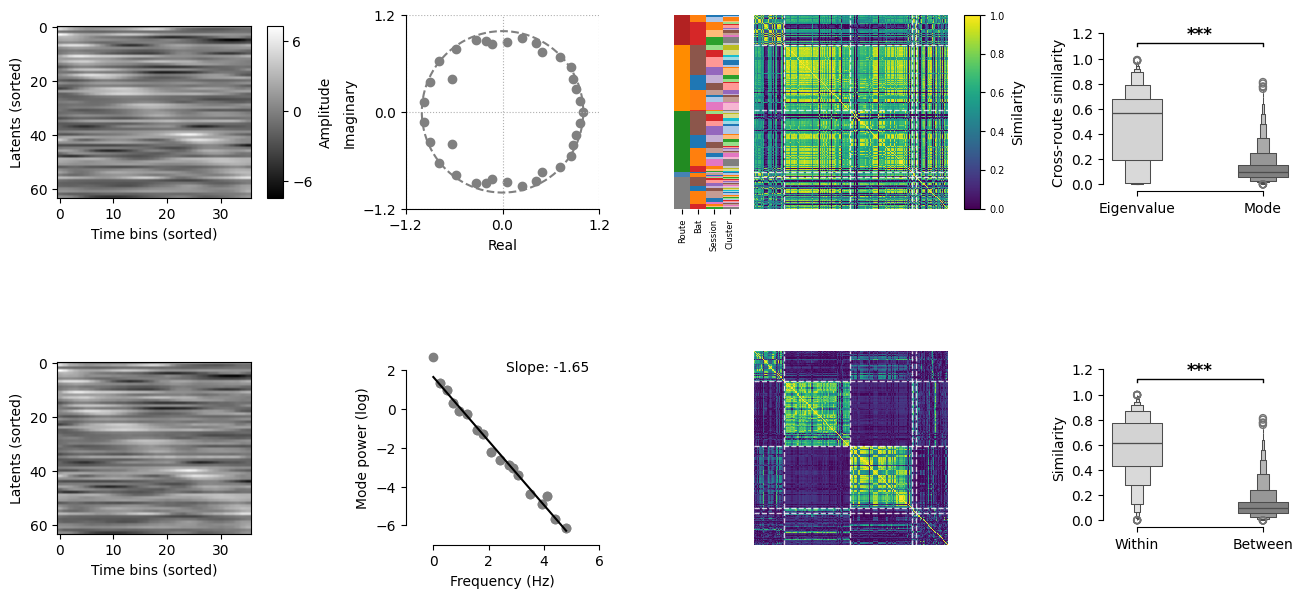

In [40]:
sorted_trajectories_dmd, sim_mat_dmdmode, sim_mat_dmdeigen, df_meta_dmd = compute_similarity_matrix_DMD(all_latents, metric='cosine')
hh = 6
top_mode_index = 1
fig, axes = plt.subplots(2, 4, figsize=(16, 8), gridspec_kw={'width_ratios': [4, 4, 4, 4], 'wspace': 0.8})

# for the first 2 columns, we show the eigenvalues and DMD mode for one example flight trace
task, ind = 'Rew->Rew', 0
mask = (df_meta_dmd['env'] == 'Indoor') & (df_meta_dmd['f_type'] == task)
raw_data = sorted_trajectories_dmd[np.where(mask.to_numpy())[0][ind]].T  # should be in the shape of (num_feature, num_time_points) for FlightDMD
flight_dmd = FlightDMD(use_stacking=True, h=hh)
flight_dmd.fit(raw_data)

# raw and reconstructed flights in the latent space
ax = axes[0,0]
time_bins = flight_dmd.reconstructed_data.shape[1]
data = flight_dmd.data[:, :time_bins] # due to shift_stacking, it drops its last h-1 time points
vmin = np.min(np.concatenate((data, flight_dmd.reconstructed_data)))
vmax = np.max(np.concatenate((data, flight_dmd.reconstructed_data)))
peak_times = []
for cc in range(len(data)):
    peak_times.append(np.argmax(data[cc]))
peak_times = np.array(peak_times)
sort_order = np.argsort(peak_times)
im = ax.imshow(data[sort_order, :], cmap='gray', vmin=vmin, vmax=vmax)
ax.set_xlabel("Time bins (sorted)")
ax.set_ylabel('Latents (sorted)')
ax.set_aspect(0.5)
pos = ax.get_position()  # [x0, y0, width, height]
cax = fig.add_axes([pos.x1 + 0.01, pos.y0, 0.01, pos.height])
cbar = fig.colorbar(im, cax=cax, ticks=[-6, 0 ,6])
cbar.set_label('Amplitude')

ax = axes[1,0]
im = ax.imshow(flight_dmd.reconstructed_data[sort_order, :], cmap='gray', vmin=vmin, vmax=vmax)
ax.set_xlabel("Time bins (sorted)")
ax.set_ylabel('Latents (sorted)')
ax.set_aspect(0.5)

# eigenvalues
ax = axes[0,1]
# Subplot A: Unit Circle Domain
theta = np.linspace(0, 2*np.pi, 100)
ax.plot(np.cos(theta), np.sin(theta), color='gray', linestyle='--')
# Scatter eigenvalues scaled by log-power amplitudes
scatter_size = 20 + 200 * (flight_dmd.power / np.max(flight_dmd.power))
# sc = ax.scatter(np.real(flight_dmd.eigenvalues), np.imag(flight_dmd.eigenvalues), 
#                         s=scatter_size, c=flight_dmd.frequencies, cmap='gray', edgecolors='k', zorder=3)
ax.scatter(np.real(flight_dmd.eigenvalues), np.imag(flight_dmd.eigenvalues), c='gray' )
ax.set_xticks([-1.2, 0, 1.2])
ax.set_yticks([-1.2, 0, 1.2])
ax.set_xlabel("Real")
ax.set_ylabel("Imaginary")
# ax.set_yticks([-1, 0, 1])
ax.grid(True, linestyle=':')
ax.set_aspect('equal')
# fig.colorbar(sc, ax=ax, label='Frequency (Hz)', shrink=0.6)
sns.despine(ax=ax, trim=True)
# ax.set_aspect(0.5)
# pos = ax.get_position()  # [x0, y0, width, height]
# cax = fig.add_axes([pos.x1 + 0.01, pos.y0, 0.01, pos.height])
# cbar = fig.colorbar(sc, cax=cax, ticks=[0 , 4])
# cbar.set_label('Frequency (Hz)')

# DMD power spectrum
ax = axes[1,1]
# 1. Linear Fit using polyfit
x = flight_dmd.frequencies
y = np.log2(flight_dmd.power)
slope, intercept = np.polyfit(x, y, 1)
# 2. Plot scatter and linear fit line
ax.scatter(x, y, c='gray')
x_vals = np.linspace(x.min(), x.max(), 100)
ax.plot(x_vals, slope * x_vals + intercept, color='k', linestyle='-')
# 3. Add text for the slope
ax.text(0.95, 0.95, f'Slope: {slope:.2f}', 
    transform=ax.transAxes, ha='right', va='top', color='k')
# --- Your existing layout code ---
ax.set_xlim(-1, 6)
ax.set_ylim(-7, 3)
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("Mode power (log)")
# ax.grid(True, linestyle=':')
ax.set_aspect(0.7)
sns.despine(ax=ax, trim=True)

# ==============================================================================
# the third column shows the spatial/temporal subspace alignment
ax = axes[0, 2]
# df_meta = df_meta_dmd.copy()
indoor_mask = (df_meta_dmd['env'] == 'Indoor').to_numpy() # only Indoor
df_meta = df_meta_dmd[indoor_mask].copy().reset_index(drop=True)
sim_matrix = np.copy(sim_mat_dmdeigen)[np.ix_(indoor_mask, indoor_mask)]
# --- Calculate Route Boundaries ---
f_type_series = df_meta['f_type'].values
route_boundaries = np.where(f_type_series[:-1] != f_type_series[1:])[0] + 1
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel('Flights (sorted)')
# Calculate vmin and vmax excluding the diagonal values
off_diagonal_vals = sim_matrix[~np.eye(sim_matrix.shape[0], dtype=bool)]
v_min = 0.0 # np.min(off_diagonal_vals)
v_max = 1.0 # np.max(off_diagonal_vals)
# Draw the main similarity matrix (cbar=False for ALL to keep shapes identical)
im = sns.heatmap(
    sim_matrix, ax=ax, cmap="viridis", cbar=False,
    vmin=v_min, vmax=v_max, xticklabels=False, yticklabels=False, square=True, rasterized=True
)
# Add the white dashed boundary lines across rows and columns
for boundary in route_boundaries:
    ax.axhline(y=boundary, color='white', linestyle='--', linewidth=1.0, alpha=0.8)
    ax.axvline(x=boundary, color='white', linestyle='--', linewidth=1.0, alpha=0.8)
# ax.set_title(titles[i])
plt.draw() # Force geometry calculations
# 4. Inject the Left Sidebar explicitly onto the first heatmap column
env_colors = get_color_sidebar(df_meta, 'env', "Set1").tolist()
type_colors = df_meta['f_type'].map(route_palette()).tolist()
bat_colors = df_meta['bat'].map(bat_palette()).tolist()
session_colors = get_color_sidebar(df_meta, 'session', "tab20").tolist()
s_cluster_colors = get_color_sidebar(df_meta, 's_cluster', "tab20").tolist()
sidebar_df = pd.DataFrame({
    # "Env": env_colors,
    "Route": type_colors,
    "Bat": bat_colors,
    "Session": session_colors,
    "Cluster": s_cluster_colors,
}, index=df_meta.index)
sidebar_rgb = colors_to_rgb_array(sidebar_df)
# 4. Inject the Left Sidebar 
heatmap_pos = ax.get_position()
sidebar_width = 0.04
sidebar_padding = 0.01
sidebar_ax = fig.add_axes([
    heatmap_pos.x0 - sidebar_width - sidebar_padding, 
    heatmap_pos.y0, 
    sidebar_width, 
    heatmap_pos.height
])
sidebar_ax.imshow(sidebar_rgb, aspect='auto', interpolation='nearest')
sidebar_ax.set_xticks(range(len(sidebar_df.columns)))
sidebar_ax.set_xticklabels(sidebar_df.columns, rotation=90, fontsize=6)
sidebar_ax.set_yticks([])
sidebar_ax.spines[:].set_visible(False)
# 5. Position the Shared Colorbar and Legend on the last column
last_heatmap_ax = ax
last_heatmap_pos = last_heatmap_ax.get_position()
cbar_ax = fig.add_axes([last_heatmap_pos.x1 + 0.01, 
    last_heatmap_pos.y0, 0.01, last_heatmap_pos.height])
cbar = fig.colorbar(last_heatmap_ax.collections[0], cax=cbar_ax)
cbar.set_label("Similarity")
cbar.ax.tick_params(labelsize=7)

ax = axes[1, 2]
# df_meta = df_meta_dmd.copy()
# sim_matrix = np.copy(sim_mat_dmdmode)
sim_matrix = np.copy(sim_mat_dmdmode)[np.ix_(indoor_mask, indoor_mask)]
# --- Calculate Route Boundaries ---
f_type_series = df_meta['f_type'].values
route_boundaries = np.where(f_type_series[:-1] != f_type_series[1:])[0] + 1
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel('Flights (sorted)')
# Calculate vmin and vmax excluding the diagonal values
off_diagonal_vals = sim_matrix[~np.eye(sim_matrix.shape[0], dtype=bool)]
# v_min = np.min(off_diagonal_vals)
# v_max = np.max(off_diagonal_vals)
# Draw the main similarity matrix (cbar=False for ALL to keep shapes identical)
im = sns.heatmap(
    sim_matrix, ax=ax, cmap="viridis", cbar=False,
    vmin=v_min, vmax=v_max, xticklabels=False, yticklabels=False, square=True, rasterized=True
)
# Add the white dashed boundary lines across rows and columns
for boundary in route_boundaries:
    ax.axhline(y=boundary, color='white', linestyle='--', linewidth=1.0, alpha=0.8)
    ax.axvline(x=boundary, color='white', linestyle='--', linewidth=1.0, alpha=0.8)
# ax.set_title(titles[i])
plt.draw() # Force geometry calculations

# ==============================================================================
# the fourth column quantifies the spatial/temporal subspace alignment
ax = axes[0,3]
_, between_eigen = extract_route_similarities(
    np.copy(sim_mat_dmdeigen)[np.ix_(indoor_mask, indoor_mask)], df_meta, exclude_types=['Other'])
_, between_spatial = extract_route_similarities(
    np.copy(sim_mat_dmdmode)[np.ix_(indoor_mask, indoor_mask)], df_meta, exclude_types=['Other'])
# Combine into a single comparison DataFrame
df_between = pd.DataFrame({
    'Similarity': np.concatenate([between_eigen, between_spatial]),
    'Feature': ['Eigenvalue\nProfile'] * len(between_eigen) + ['Spatial\nMode'] * len(between_spatial)})
sns.boxenplot(
    data=df_between, x='Feature', y='Similarity', hue='Feature',
    palette=['lightgray', 'gray'], legend=False, outlier_prop=0.05, width=0.4, ax=ax)
stat, p_val = stats.mannwhitneyu(between_eigen, between_spatial, alternative='greater')
add_significance_bracket(ax, x1=0, x2=1, p=p_val, y=1.10, height_frac=0.02)
ax.set_ylabel("Cross-route similarity")
ax.set_xlabel('')  
ax.set_xticks([0, 1])  
ax.set_xticklabels(['Eigenvalue', 'Mode'])
ax.set_aspect(1.0)
sns.despine(ax=ax, trim=True)

ax = axes[1,3]
sim_matrix = np.copy(sim_mat_dmdmode)[np.ix_(indoor_mask, indoor_mask)]
within_vals, between_vals = extract_route_similarities(sim_matrix, df_meta, exclude_types=['Other'])
df_plot = pd.DataFrame({
    'Similarity': np.concatenate([within_vals, between_vals]),
    'Comparison': ['Within Route'] * len(within_vals) + ['Between Route'] * len(between_vals)
})
# 2. Draw Boxenplot
sns.boxenplot(data=df_plot, x='Comparison', y='Similarity', hue='Comparison',
              palette=['lightgray', 'gray'], legend=False, outlier_prop=0.05, width=0.4, ax=ax)
# 3. Compute Stats & Add Significance Bracket
stat, p_val = stats.mannwhitneyu(within_vals, between_vals, alternative='two-sided')
add_significance_bracket(ax, x1=0, x2=1, p=p_val, y=1.10, height_frac=0.02)
# 4. Clean Aesthetics
# ax.set_title('Eigenvalue profile')
ax.set_ylabel('Similarity')
ax.set_xlabel('')  
ax.set_xticks([0, 1])  
ax.set_xticklabels(['Within', 'Between'])
ax.set_aspect(1.0)
sns.despine(ax=ax, trim=True)


# plt.savefig(f"./out-figures/fig3-DMD.svg", dpi=300)
# plt.savefig(f"./out-figures/fig3-DMD.png", dpi=300)

/tmp/ipykernel_701067/4124512981.py:137: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['Temporal', 'Spatial'])


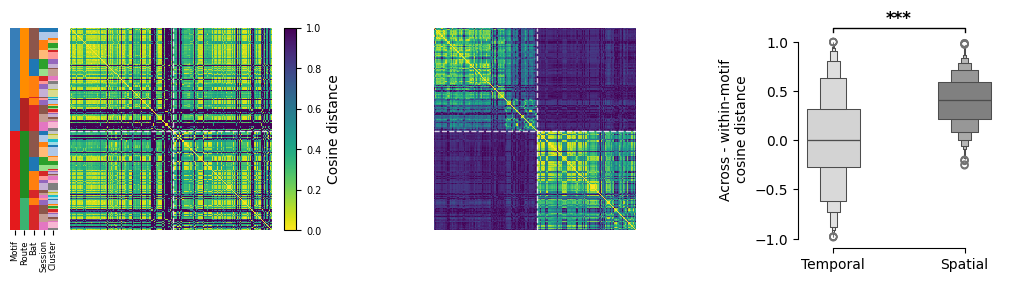

In [29]:
sorted_trajectories_dmd, sim_mat_dmdmode, sim_mat_dmdeigen, df_meta_dmd = compute_similarity_matrix_DMD_motif(all_latents, metric='cosine')

fig, axes = plt.subplots(1, 3, figsize=(12, 4), gridspec_kw={'width_ratios': [4, 4, 4], 'wspace': 0.8})
# ========================== temporal subspace alignment =======================================
ax = axes[0]
# df_meta = df_meta_dmd.copy()
# indoor_mask = (df_meta_dmd['env'] == 'Indoor').to_numpy() # only Indoor
indoor_mask = ((df_meta_dmd['env'] == 'Indoor') & (df_meta_dmd['motif'] != 'Other')).to_numpy() # only Indoor, also excluding 'Other' motifs
df_meta = df_meta_dmd[indoor_mask].copy().reset_index(drop=True)
sim_matrix = 1.0 - np.copy(sim_mat_dmdeigen)[np.ix_(indoor_mask, indoor_mask)]
# --- Calculate Motif and Route Boundaries ---
motif_series = df_meta['motif'].values
motif_boundaries = np.where(motif_series[:-1] != motif_series[1:])[0] + 1
f_type_series = df_meta['f_type'].values
route_boundaries = np.where(f_type_series[:-1] != f_type_series[1:])[0] + 1
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel('Motifs (sorted)')
# Calculate vmin and vmax excluding the diagonal values
off_diagonal_vals = sim_matrix[~np.eye(sim_matrix.shape[0], dtype=bool)]
v_min = 0.0 # np.min(off_diagonal_vals)
v_max = 1.0 # np.max(off_diagonal_vals)
# Draw the main similarity matrix (cbar=False for ALL to keep shapes identical)
im = sns.heatmap(
    sim_matrix, ax=ax, cmap="viridis_r", cbar=False,
    vmin=v_min, vmax=v_max, xticklabels=False, yticklabels=False, square=True, rasterized=True
)
# Add the white dashed boundary lines across rows and columns
for boundary in motif_boundaries:
    ax.axhline(y=boundary, color='white', linestyle='--', linewidth=1.0, alpha=0.8)
    ax.axvline(x=boundary, color='white', linestyle='--', linewidth=1.0, alpha=0.8)
# ax.set_title(titles[i])
plt.draw() # Force geometry calculations
# 4. Inject the Left Sidebar explicitly onto the first heatmap column
env_colors = get_color_sidebar(df_meta, 'env', "Set1").tolist()
motif_colors = df_meta['motif'].map(motif_palette()).tolist()
type_colors = df_meta['f_type'].map(route_palette_motif()).tolist()
bat_colors = df_meta['bat'].map(bat_palette()).tolist()
session_colors = get_color_sidebar(df_meta, 'session', "tab20").tolist()
s_cluster_colors = get_color_sidebar(df_meta, 's_cluster', "tab20").tolist()
sidebar_df = pd.DataFrame({
    # "Env": env_colors,
    "Motif": motif_colors,
    "Route": type_colors,
    "Bat": bat_colors,
    "Session": session_colors,
    "Cluster": s_cluster_colors,
}, index=df_meta.index)
sidebar_rgb = colors_to_rgb_array(sidebar_df)
# 4. Inject the Left Sidebar 
heatmap_pos = ax.get_position()
sidebar_width = 0.04
sidebar_padding = 0.01
sidebar_ax = fig.add_axes([
    heatmap_pos.x0 - sidebar_width - sidebar_padding, 
    heatmap_pos.y0, 
    sidebar_width, 
    heatmap_pos.height
])
sidebar_ax.imshow(sidebar_rgb, aspect='auto', interpolation='nearest')
sidebar_ax.set_xticks(range(len(sidebar_df.columns)))
sidebar_ax.set_xticklabels(sidebar_df.columns, rotation=90, fontsize=6)
sidebar_ax.set_yticks([])
sidebar_ax.spines[:].set_visible(False)
# 5. Position the Shared Colorbar and Legend on the last column
last_heatmap_ax = ax
last_heatmap_pos = last_heatmap_ax.get_position()
cbar_ax = fig.add_axes([last_heatmap_pos.x1 + 0.01, 
    last_heatmap_pos.y0, 0.01, last_heatmap_pos.height])
cbar = fig.colorbar(last_heatmap_ax.collections[0], cax=cbar_ax)
cbar.set_label("Cosine distance")
cbar.ax.tick_params(labelsize=7)

# ========================== spatial subspace alignment =========================================
ax = axes[1]
# df_meta = df_meta_dmd.copy()
# sim_matrix = np.copy(sim_mat_dmdmode)
sim_matrix = 1.0 - np.copy(sim_mat_dmdmode)[np.ix_(indoor_mask, indoor_mask)]
# --- Calculate Route Boundaries ---
f_type_series = df_meta['f_type'].values
# route_boundaries = np.where(f_type_series[:-1] != f_type_series[1:])[0] + 1
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel('Motifs (sorted)')
# Calculate vmin and vmax excluding the diagonal values
off_diagonal_vals = sim_matrix[~np.eye(sim_matrix.shape[0], dtype=bool)]
# v_min = np.min(off_diagonal_vals)
# v_max = np.max(off_diagonal_vals)
# Draw the main similarity matrix (cbar=False for ALL to keep shapes identical)
im = sns.heatmap(
    sim_matrix, ax=ax, cmap="viridis_r", cbar=False,
    vmin=v_min, vmax=v_max, xticklabels=False, yticklabels=False, square=True, rasterized=True
)
# Add the white dashed boundary lines across rows and columns
for boundary in motif_boundaries:
    ax.axhline(y=boundary, color='white', linestyle='--', linewidth=1.0, alpha=0.8)
    ax.axvline(x=boundary, color='white', linestyle='--', linewidth=1.0, alpha=0.8)
# ax.set_title(titles[i])
plt.draw() # Force geometry calculations

# =====================================================================
ax = axes[2]
# 1. Extract Between Motif similarities for Temporal & Spatial matrices
within_eigen, between_eigen = extract_motif_similarities(
    np.copy(sim_mat_dmdeigen)[np.ix_(indoor_mask, indoor_mask)], 
    df_meta, exclude_types=['Other'])
within_spatial, between_spatial = extract_motif_similarities(
    np.copy(sim_mat_dmdmode)[np.ix_(indoor_mask, indoor_mask)], 
    df_meta, exclude_types=['Other'])
within_eigen = 1.0 - within_eigen
between_eigen = 1.0 - between_eigen
within_spatial = 1.0 - within_spatial
between_spatial = 1.0 - between_spatial
num = np.min([len(temp) for temp in [within_eigen, between_eigen, within_spatial, between_spatial]])
np.random.seed(10)
ind_within_eigen = np.random.choice(len(within_eigen), num)
ind_between_eigen = np.random.choice(len(between_eigen), num)
ind_within_spatial = np.random.choice(len(within_spatial), num)
ind_between_spatial = np.random.choice(len(between_spatial), num)

# 2. Combine into a single DataFrame for plotting
df_plot = pd.DataFrame({
    'Similarity': np.concatenate([between_eigen[ind_between_eigen] - within_eigen[ind_within_eigen], 
        between_spatial[ind_between_spatial] - within_spatial[ind_within_spatial]]),
    'Feature': ['Temporal'] * len(between_eigen[ind_between_eigen]) + ['Spatial'] * len(between_spatial[ind_between_spatial])})
# 3. Draw Boxenplot
sns.boxenplot(
    data=df_plot, x='Feature', y='Similarity', hue='Feature',
    palette=['lightgray', 'gray'], legend=False, outlier_prop=0.05, width=0.4, ax=ax)
# 4. Compute Stats & Add Significance Bracket
stat, p_val = stats.mannwhitneyu(between_eigen, between_spatial, alternative='two-sided')
add_significance_bracket(ax, x1=0, x2=1, p=p_val, y=1.10, height_frac=0.02)
# 5. Clean Aesthetics
ax.set_ylabel('Across - within-motif\ncosine distance')
ax.set_xlabel('')
# ax.set_xticks([0, 1])
ax.set_xticklabels(['Temporal', 'Spatial'])
ax.set_aspect(0.75)
sns.despine(ax=ax, trim=True)